# Multiclass Network Intrusion Detection System (NIDS)
## UNSW-NB15 — data quality, model benchmarking and per-class evaluation

This notebook implements a file-based, ten-class network intrusion detection workflow using `attack_cat` as the prediction target. It retains the established preprocessing and data-audit pipeline, keeps unweighted XGBoost as a reference candidate, and compares tree ensembles and gradient-boosted models, including class-weighted variants. CatBoost is excluded to keep execution practical.

The workflow audits schema and labels, missing and invalid values, class imbalance, zero-heavy features, outliers, duplicate feature groups, conflicting labels, correlations and train/validation group coverage. Model comparisons report accuracy, macro precision, macro recall, Macro-F1, weighted F1, false-positive measures and runtime.

The default fast screening uses two duplicate-grouped folds sampled from training groups and reduced estimator counts. Candidates are compared using a transparent multi-metric rule: Macro-F1 is optimized among configurations whose mean validation accuracy is within a predeclared 1.5 percentage-point band of the best candidate. This provides a practical balance between overall correctness and performance across minority attack categories. The official test partition is not used for model selection.

After selection, the chosen pipeline is refitted on the complete training partition and evaluated once on the official testing partition. Training-only validation data is used for feature importance, TTL ablation and corruption experiments. Post-evaluation test diagnostics are descriptive only and must not be used to retune the model.

The GUI uses the same feature-preparation function as training. This is an offline CSV/JSON-based prototype; it does not capture live packets, block connections or automatically respond to attacks. All reported performance values are measured results; no accuracy or F1 score is guaranteed.

## 1. Install dependencies

Run this cell in a fresh Google Colab runtime. It installs NumPy, Pandas, scikit-learn, SciPy, Matplotlib, Joblib, LightGBM, XGBoost and Gradio. The model set uses XGBoost, LightGBM, Random Forest and ExtraTrees. CatBoost is deliberately excluded to keep runtime manageable.


In [1]:
%pip -q install "numpy>=1.26" "pandas>=2.1" "scikit-learn>=1.4,<2" "scipy>=1.11" "matplotlib>=3.8" "joblib>=1.3" "lightgbm>=4,<5" "xgboost>=2,<4" "gradio>=4.44,<6"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 2.12.1 requires pydantic<3.0.0,>=2.12.5, but you have pydantic 2.12.3 which is incompatible.
hf-gradio 0.4.1 requires gradio-client<3.0,>=2.0, but you have gradio-client 1.14.0 which is incompatible.
google-adk 2.7.1 requires starlette<2,>=1.3.1, but you have starlette 0.52.1 which is incompatible.
python-fasthtml 0.14.18 requires starlette>=1.0.1, but you have starlette 0.52.1 which is incompatible.


## 2. Imports, reproducibility and experiment configuration

`QUICK_RUN=False` uses the complete official training partition. `FAST_MODE=True` screens nine candidate configurations with two sampled duplicate-grouped folds and reduced estimator counts. The comparison reports accuracy, macro precision, macro recall, Macro-F1, weighted F1, false-positive measures and fit time. The selected configuration maximizes Macro-F1 among candidates within the predeclared validation-accuracy tolerance. Diagnostic analyses use training-only grouped validation data. The official test partition is reserved for final evaluation.

In [2]:
import os, io, json, time, math, gc, shutil, zipfile, warnings, unittest
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, confusion_matrix, precision_recall_fscore_support,
    f1_score, matthews_corrcoef, log_loss, roc_auc_score,
    average_precision_score
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from scipy.stats import ks_2samp
from IPython.display import display
from google.colab import files

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
FAST_MODE = True
# Fast mode uses two sampled grouped screening folds; full mode uses five-fold confirmation.
N_SPLITS = 2 if FAST_MODE else 5
# Fast screening uses two sampled, duplicate-grouped folds.
SCREEN_SPLITS = 2 if FAST_MODE else 3
FAST_SCREEN_GROUP_FRACTION = 0.20
FAST_SCREEN_MIN_GROUPS_PER_CLASS = 20
TARGET = "attack_cat"
EXCLUDED_PREDICTORS = ["id", "label", "attack_cat"]
EXPECTED_UNSW_CLASSES = [
    "Analysis", "Backdoor", "DoS", "Exploits", "Fuzzers",
    "Generic", "Normal", "Reconnaissance", "Shellcode", "Worms"
]
KNOWN_CATEGORICAL = ["proto", "service", "state"]

QUICK_RUN = False
QUICK_FRACTION = 0.20
SELECTION_METRIC = "macro_f1"
ACCURACY_TOLERANCE = 0.015
SCREENING_FINALISTS = 1 if FAST_MODE else 2
PREPROCESSING_FINALISTS = 0 if FAST_MODE else 2

RF_TREES = 300
EXTRA_TREES = 250
HGB_ITERATIONS = 150
LOGISTIC_MAX_ITER = 250
LIGHTGBM_TREES = 700
XGBOOST_TREES = 600
MILD_CLASS_WEIGHT_EXPONENT = 0.35
DIAGNOSTIC_FOLD_INDEX = 0
IMPORTANCE_SAMPLE_SIZE = 1000
IMPORTANCE_REPEATS = 2
STRATEGIES = ["S0_Raw", "S1_Clipping", "S2_SignedLog"]

CANDIDATE_MODELS = [
    "Logistic Regression", "Random Forest (Balanced)",
    "Random Forest (Unweighted)", "ExtraTrees", "ExtraTrees (Unweighted)",
    "HistGradientBoosting", "LightGBM (Balanced)",
    "LightGBM (Unweighted)", "LightGBM (Mild Weights)",
    "LightGBM (Regularized)", "XGBoost (Balanced)",
    "XGBoost (Unweighted)", "XGBoost (Mild Weights)",
    "XGBoost (Regularized)", "Soft Voting (Unweighted)"
]
FAST_CANDIDATE_MODELS = [
    "Random Forest (Unweighted)",
    "ExtraTrees (Unweighted)",
    "LightGBM (Unweighted)",
    "LightGBM (Regularized)",
    "LightGBM (Mild Weights)",
    "XGBoost (Unweighted)",
    "XGBoost (Regularized)",
    "XGBoost (Mild Weights)",
    "Soft Voting (Unweighted)"
]
ACTIVE_CANDIDATE_MODELS = FAST_CANDIDATE_MODELS if FAST_MODE else CANDIDATE_MODELS.copy()

ROOT = Path("/content/Robust_NIDS_UNSW_NB15_F1_Analysis")
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"
MODELS_DIR = ROOT / "models"
for folder in [DATA_DIR, METRICS_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Configuration ready.")
print("All implemented candidates:", len(CANDIDATE_MODELS))
print("Candidates active in this run:", ACTIVE_CANDIDATE_MODELS)
print("FAST_MODE =", FAST_MODE, "| SCREENING_FOLDS =", SCREEN_SPLITS, "| FULL_DATA_FOLDS =", N_SPLITS)
if FAST_MODE:
    print(f"Fast screening samples about {FAST_SCREEN_GROUP_FRACTION:.0%} of duplicate groups per class (minimum {FAST_SCREEN_MIN_GROUPS_PER_CLASS} groups/class) and uses reduced estimator counts.")
    print("Set FAST_MODE = False for the longer 3-fold screen + 5-fold confirmation + preprocessing study.")
print("Selection = maximize Macro-F1 within an accuracy guardrail of", f"{100*ACCURACY_TOLERANCE:.1f} percentage points")
print("Official test set will not be used for selection or diagnostic tuning.")
print("QUICK_RUN =", QUICK_RUN)

Configuration ready.
All implemented candidates: 15
Candidates active in this run: ['Random Forest (Unweighted)', 'ExtraTrees (Unweighted)', 'LightGBM (Unweighted)', 'LightGBM (Regularized)', 'LightGBM (Mild Weights)', 'XGBoost (Unweighted)', 'XGBoost (Regularized)', 'XGBoost (Mild Weights)', 'Soft Voting (Unweighted)']
FAST_MODE = True | SCREENING_FOLDS = 2 | FULL_DATA_FOLDS = 2
Fast screening samples about 20% of duplicate groups per class (minimum 20 groups/class) and uses reduced estimator counts.
Set FAST_MODE = False for the longer 3-fold screen + 5-fold confirmation + preprocessing study.
Selection = maximize Macro-F1 within an accuracy guardrail of 1.5 percentage points
Official test set will not be used for selection or diagnostic tuning.
QUICK_RUN = False


## 3. Upload and validate both official datasets

Upload the training and testing CSVs together. File suffixes such as `(1)` are accepted. The notebook uses `attack_cat` as the multiclass target and excludes `id` and binary `label` from the predictor matrix.

In [3]:
# Upload the two official CSV files together.
uploaded = files.upload()
csv_paths = [Path("/content") / name for name in uploaded if name.lower().endswith(".csv")]
train_candidates = [p for p in csv_paths if "train" in p.name.lower() and "test" not in p.name.lower()]
test_candidates = [p for p in csv_paths if "test" in p.name.lower()]
if len(train_candidates) != 1 or len(test_candidates) != 1:
    raise ValueError(
        "Upload exactly one training CSV and one testing CSV. "
        f"Detected {len(train_candidates)} training and {len(test_candidates)} testing files."
    )
TRAIN_PATH, TEST_PATH = train_candidates[0], test_candidates[0]
train_df = pd.read_csv(TRAIN_PATH, low_memory=False)
test_df = pd.read_csv(TEST_PATH, low_memory=False)

def clean_column_names(frame, partition_name):
    frame = frame.copy()
    cleaned = [str(c).strip() for c in frame.columns]
    duplicated = pd.Index(cleaned)[pd.Index(cleaned).duplicated()].unique().tolist()
    if duplicated:
        raise ValueError(f"{partition_name} contains duplicate column names after trimming: {duplicated}")
    frame.columns = cleaned
    return frame

train_df = clean_column_names(train_df, "Training CSV")
test_df = clean_column_names(test_df, "Testing CSV")
required_meta = {"id", "label", TARGET}
missing_meta_train = sorted(required_meta - set(train_df.columns))
missing_meta_test = sorted(required_meta - set(test_df.columns))
if missing_meta_train or missing_meta_test:
    raise ValueError(
        f"Required metadata columns missing. Training={missing_meta_train}; testing={missing_meta_test}"
    )

RAW_FEATURE_COLUMNS = [c for c in train_df.columns if c not in EXCLUDED_PREDICTORS]
missing_test_features = sorted(set(RAW_FEATURE_COLUMNS) - set(test_df.columns))
extra_test_columns = sorted(set(test_df.columns) - set(train_df.columns))
if missing_test_features:
    raise ValueError(f"Testing CSV is missing required predictor columns: {missing_test_features}")
if not RAW_FEATURE_COLUMNS:
    raise ValueError("No predictor columns were found after excluding id, label and attack_cat.")

missing_train_target = int(train_df[TARGET].isna().sum())
missing_test_target = int(test_df[TARGET].isna().sum())
if missing_train_target or missing_test_target:
    raise ValueError(
        "Target values are missing. Do not silently drop labelled records. "
        f"Training missing={missing_train_target}; testing missing={missing_test_target}."
    )

def normalize_target_values(series, split_name):
    canonical = {name.casefold(): name for name in EXPECTED_UNSW_CLASSES}
    cleaned = series.astype("string").str.strip()
    normalized = cleaned.str.casefold().map(canonical)
    unknown = sorted(cleaned[normalized.isna()].dropna().unique().tolist())
    if unknown:
        raise ValueError(f"Unknown {split_name} target labels: {unknown}")
    return normalized.astype(str)

y_train_full = normalize_target_values(train_df[TARGET], "training")
classes = sorted(y_train_full.unique().tolist())
if set(classes) != set(EXPECTED_UNSW_CLASSES):
    raise ValueError(
        "Training data does not contain the expected ten UNSW-NB15 classes. "
        f"Found={classes}; expected={EXPECTED_UNSW_CLASSES}"
    )

categorical_columns = [c for c in KNOWN_CATEGORICAL if c in RAW_FEATURE_COLUMNS]
missing_known_categories = sorted(set(KNOWN_CATEGORICAL) - set(categorical_columns))
if missing_known_categories:
    raise ValueError(f"Expected categorical predictors are missing: {missing_known_categories}")
raw_numeric_columns = [c for c in RAW_FEATURE_COLUMNS if c not in categorical_columns]

conversion_rows = []
def coerce_raw_predictors(frame, partition_name="prediction"):
    """Canonical raw-feature preparation shared by training, diagnostics and GUI."""
    frame = frame.copy()
    frame.columns = [str(c).strip() for c in frame.columns]
    duplicated = pd.Index(frame.columns)[pd.Index(frame.columns).duplicated()].unique().tolist()
    if duplicated:
        raise ValueError(f"Input contains duplicate column names: {duplicated}")
    missing = [c for c in RAW_FEATURE_COLUMNS if c not in frame.columns]
    if missing:
        raise ValueError("Missing required traffic features: " + ", ".join(missing))
    raw = frame.reindex(columns=RAW_FEATURE_COLUMNS).copy()
    quality_rows = []
    for col in raw_numeric_columns:
        original = raw[col]
        converted = pd.to_numeric(original, errors="coerce")
        invalid_text = int((original.notna() & converted.isna()).sum())
        infinite_count = int(np.isinf(converted.to_numpy(dtype=float, na_value=np.nan)).sum())
        negative_count = int((converted < 0).fillna(False).sum())
        converted = converted.replace([np.inf, -np.inf], np.nan)
        raw[col] = converted
        quality_rows.append({
            "partition": partition_name, "feature": col,
            "invalid_numeric_cells": invalid_text,
            "infinite_cells": infinite_count,
            "negative_cells": negative_count,
            "missing_after_conversion": int(raw[col].isna().sum())
        })
    for col in categorical_columns:
        values = raw[col].astype("string").str.strip()
        values = values.mask(values.eq(""), pd.NA)
        raw[col] = values.astype(object).where(values.notna(), np.nan)
        quality_rows.append({
            "partition": partition_name, "feature": col,
            "invalid_numeric_cells": 0, "infinite_cells": 0,
            "negative_cells": 0,
            "missing_after_conversion": int(raw[col].isna().sum())
        })
    return raw, quality_rows

def add_traffic_features(frame):
    """Create deterministic traffic aggregates; no target or identifier is used."""
    result = frame.copy()
    def numeric(name):
        return pd.to_numeric(result[name], errors="coerce")
    if {"sbytes", "dbytes"}.issubset(result.columns):
        src, dst = numeric("sbytes"), numeric("dbytes")
        result["derived_total_bytes"] = src + dst
        result["derived_src_dst_byte_log_ratio"] = np.log1p(src.clip(lower=0)) - np.log1p(dst.clip(lower=0))
    if {"spkts", "dpkts"}.issubset(result.columns):
        src, dst = numeric("spkts"), numeric("dpkts")
        result["derived_total_packets"] = src + dst
        result["derived_src_dst_packet_log_ratio"] = np.log1p(src.clip(lower=0)) - np.log1p(dst.clip(lower=0))
    if {"sbytes", "dbytes", "spkts", "dpkts"}.issubset(result.columns):
        total_bytes = numeric("sbytes") + numeric("dbytes")
        total_packets = numeric("spkts") + numeric("dpkts")
        result["derived_mean_bytes_per_packet"] = total_bytes / total_packets.clip(lower=1)
    if {"sbytes", "dbytes", "spkts", "dpkts", "dur"}.issubset(result.columns):
        total_bytes = numeric("sbytes") + numeric("dbytes")
        total_packets = numeric("spkts") + numeric("dpkts")
        safe_duration = numeric("dur").clip(lower=0) + 1e-6
        result["derived_bytes_per_duration"] = total_bytes / safe_duration
        result["derived_packets_per_duration"] = total_packets / safe_duration
    return result

X_train_raw, train_conversion_rows = coerce_raw_predictors(train_df, "training")
X_test_raw, test_conversion_rows = coerce_raw_predictors(test_df, "testing")
TRAIN_INGESTION_CONVERSION_REPORT = pd.DataFrame(train_conversion_rows)
TEST_INGESTION_CONVERSION_REPORT = pd.DataFrame(test_conversion_rows)
X_train_full = add_traffic_features(X_train_raw)
DERIVED_FEATURE_COLUMNS = [c for c in X_train_full.columns if c not in RAW_FEATURE_COLUMNS]
feature_columns = list(X_train_full.columns)
numeric_columns = [c for c in feature_columns if c not in categorical_columns]

for col in numeric_columns:
    X_train_full[col] = pd.to_numeric(X_train_full[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
X_test = add_traffic_features(X_test_raw).reindex(columns=feature_columns)
for col in numeric_columns:
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce").replace([np.inf, -np.inf], np.nan)

# Single canonical preparation path, also used by the GUI and grouped permutation analysis.
def prepare_model_features(raw_frame):
    raw, _ = coerce_raw_predictors(raw_frame, "inference")
    engineered = add_traffic_features(raw).reindex(columns=feature_columns)
    for col in numeric_columns:
        engineered[col] = pd.to_numeric(engineered[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
    return engineered

# Cross-check the excluded binary label against attack_cat on the training partition only.
train_binary_label = pd.to_numeric(train_df["label"], errors="coerce")
expected_binary_label = (y_train_full != "Normal").astype(int)
label_mismatch_count = int((train_binary_label.fillna(-999).to_numpy() != expected_binary_label.to_numpy()).sum())

SCHEMA_REPORT = {
    "training_file": TRAIN_PATH.name,
    "testing_file": TEST_PATH.name,
    "training_rows": int(len(train_df)),
    "testing_rows": int(len(test_df)),
    "training_columns": int(len(train_df.columns)),
    "testing_columns": int(len(test_df.columns)),
    "raw_predictor_count": int(len(RAW_FEATURE_COLUMNS)),
    "excluded_columns": EXCLUDED_PREDICTORS,
    "extra_testing_columns_ignored": extra_test_columns,
    "missing_test_predictors": missing_test_features,
    "training_target_missing": missing_train_target,
    "testing_target_missing": missing_test_target,
    "training_binary_label_target_mismatches": label_mismatch_count
}

assert not set(EXCLUDED_PREDICTORS).intersection(X_train_full.columns)
assert list(X_train_full.columns) == list(X_test.columns)
assert X_train_full.shape[1] == len(RAW_FEATURE_COLUMNS) + len(DERIVED_FEATURE_COLUMNS)
print(f"Training: {len(X_train_full):,} rows | Testing: {len(X_test):,} rows")
print(f"Raw predictors: {len(RAW_FEATURE_COLUMNS)} | Derived: {len(DERIVED_FEATURE_COLUMNS)} | Total: {len(feature_columns)}")
print(f"Numeric: {len(numeric_columns)} | Categorical: {len(categorical_columns)}")
print("Ten classes in training:", classes)
print("Training label-vs-attack_cat inconsistencies:", label_mismatch_count)
print("Test labels are not used for model selection; they are checked at final evaluation.")

Saving UNSW_NB15_training-set.csv to UNSW_NB15_training-set.csv
Saving UNSW_NB15_testing-set.csv to UNSW_NB15_testing-set.csv
Training: 175,341 rows | Testing: 82,332 rows
Raw predictors: 42 | Derived: 7 | Total: 49
Numeric: 46 | Categorical: 3
Ten classes in training: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']
Training label-vs-attack_cat inconsistencies: 0
Test labels are not used for model selection; they are checked at final evaluation.


## 4. Data audit and duplicate-aware fold groups

The audit records missingness, duplicate feature rows, class distributions, and conflicting labels for identical feature rows. Identical feature rows are assigned to one group so they cannot be split between training and validation portions of a CV fold.

In [4]:
# The modelling audit is training-only. Test-set metrics and labels are deliberately not inspected here.
train_row_indices = np.arange(len(X_train_full), dtype=int)
raw_group_hashes_full = pd.util.hash_pandas_object(
    X_train_raw, index=False, categorize=True
).astype("uint64").to_numpy()

duplicate_feature_rows = int(X_train_raw.duplicated().sum())
exact_duplicate_full_rows = int(train_df.duplicated().sum())
label_group_frame = pd.DataFrame({"group_hash": raw_group_hashes_full, "target": y_train_full.to_numpy()})
group_stats = label_group_frame.groupby("group_hash").agg(
    rows=("target", "size"), unique_labels=("target", "nunique"),
    labels=("target", lambda values: " | ".join(sorted(set(values))))
).reset_index()
conflicting_groups = group_stats[group_stats["unique_labels"] > 1].copy()
conflicting_duplicate_groups = int(len(conflicting_groups))
rows_in_conflicting_groups = int(conflicting_groups["rows"].sum())
repeated_groups = int((group_stats["rows"] > 1).sum())

class_counts = y_train_full.value_counts().reindex(classes, fill_value=0)
class_distribution = pd.DataFrame({
    "attack_cat": classes,
    "count": [int(class_counts[c]) for c in classes],
    "percentage": [float(class_counts[c] / len(y_train_full) * 100) for c in classes]
})
class_unique_groups = label_group_frame.drop_duplicates(["group_hash", "target"]).groupby("target").size()
class_distribution["unique_feature_groups"] = class_distribution["attack_cat"].map(class_unique_groups).fillna(0).astype(int)
class_distribution["duplicate_rows_over_first_occurrence"] = (
    class_distribution["count"] - class_distribution["unique_feature_groups"]
).clip(lower=0)
_inverse_frequency = len(y_train_full) / (len(classes) * class_counts)
_mild_weights = (_inverse_frequency.astype(float) ** MILD_CLASS_WEIGHT_EXPONENT)
_mild_weights = _mild_weights / np.average(_mild_weights, weights=class_counts)
class_distribution["mild_class_weight_factor"] = class_distribution["attack_cat"].map(_mild_weights).astype(float)
class_distribution.to_csv(METRICS_DIR / "training_class_distribution.csv", index=False)

# Per-feature data quality profile: missingness, invalid values, zeros, ranges and IQR outliers.
quality_rows = []
for col in feature_columns:
    series = X_train_full[col]
    row = {
        "feature": col,
        "feature_type": "categorical" if col in categorical_columns else "numeric",
        "dtype": str(series.dtype),
        "missing_count": int(series.isna().sum()),
        "missing_percent": float(series.isna().mean() * 100),
        "unique_values": int(series.nunique(dropna=True))
    }
    if col in numeric_columns:
        values = pd.to_numeric(series, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
        if len(values):
            q01, q25, median, q75, q99 = values.quantile([0.01, 0.25, 0.50, 0.75, 0.99])
            iqr = float(q75 - q25)
            outlier_count = int(((values < q25 - 1.5 * iqr) | (values > q75 + 1.5 * iqr)).sum()) if iqr > 0 else 0
            row.update({
                "zero_count": int((values == 0).sum()),
                "zero_percent": float((values == 0).mean() * 100),
                "negative_count": int((values < 0).sum()),
                "minimum": float(values.min()), "q01": float(q01),
                "q25": float(q25), "median": float(median),
                "q75": float(q75), "q99": float(q99),
                "maximum": float(values.max()),
                "iqr_outlier_count": outlier_count,
                "iqr_outlier_percent": float(outlier_count / len(values) * 100),
                "skewness": float(values.skew()) if len(values) > 2 else np.nan
            })
        else:
            row.update({k: np.nan for k in ["zero_count", "zero_percent", "negative_count", "minimum", "q01", "q25", "median", "q75", "q99", "maximum", "iqr_outlier_count", "iqr_outlier_percent", "skewness"]})
    else:
        mode = series.mode(dropna=True)
        row.update({
            "zero_count": np.nan, "zero_percent": np.nan,
            "negative_count": np.nan, "minimum": np.nan, "q01": np.nan,
            "q25": np.nan, "median": np.nan, "q75": np.nan, "q99": np.nan,
            "maximum": np.nan, "iqr_outlier_count": np.nan,
            "iqr_outlier_percent": np.nan, "skewness": np.nan,
            "most_frequent_value": str(mode.iloc[0]) if len(mode) else "",
            "most_frequent_percent": float(series.value_counts(normalize=True).iloc[0] * 100) if series.notna().any() else np.nan
        })
    quality_rows.append(row)
feature_quality_report = pd.DataFrame(quality_rows)
feature_quality_report.to_csv(METRICS_DIR / "feature_quality_profile.csv", index=False)
TRAIN_INGESTION_CONVERSION_REPORT.to_csv(METRICS_DIR / "training_numeric_conversion_quality.csv", index=False)

categorical_rows = []
for col in categorical_columns:
    counts = X_train_raw[col].value_counts(dropna=False)
    for value, count in counts.items():
        categorical_rows.append({
            "feature": col, "category": "__MISSING__" if pd.isna(value) else str(value),
            "count": int(count), "percentage": float(count / len(X_train_raw) * 100)
        })
categorical_levels = pd.DataFrame(categorical_rows)
categorical_levels.to_csv(METRICS_DIR / "categorical_level_frequencies.csv", index=False)

# High-correlation pairs are descriptive only; no feature is dropped automatically.
correlation = X_train_full[numeric_columns].corr(method="spearman")
corr_pairs = []
cols = list(correlation.columns)
for i, left in enumerate(cols):
    for right in cols[i + 1:]:
        value = correlation.loc[left, right]
        if pd.notna(value) and abs(float(value)) >= 0.95:
            corr_pairs.append({"feature_1": left, "feature_2": right, "spearman_correlation": float(value)})
high_corr_df = pd.DataFrame(corr_pairs).sort_values("spearman_correlation", key=lambda x: x.abs(), ascending=False) if corr_pairs else pd.DataFrame(columns=["feature_1", "feature_2", "spearman_correlation"])
high_corr_df.to_csv(METRICS_DIR / "high_correlation_pairs.csv", index=False)

# Also report raw/raw correlations separately. The full 46-column numeric set
# includes deterministic engineered features, which can add expected
# correlations by construction.
raw_correlation = X_train_raw[raw_numeric_columns].corr(method="spearman")
raw_corr_pairs = []
raw_cols = list(raw_correlation.columns)
for i, left in enumerate(raw_cols):
    for right in raw_cols[i + 1:]:
        value = raw_correlation.loc[left, right]
        if pd.notna(value) and abs(float(value)) >= 0.95:
            raw_corr_pairs.append({
                "feature_1": left, "feature_2": right,
                "spearman_correlation": float(value)
            })
raw_high_corr_df = pd.DataFrame(raw_corr_pairs).sort_values(
    "spearman_correlation", key=lambda x: x.abs(), ascending=False
) if raw_corr_pairs else pd.DataFrame(columns=["feature_1", "feature_2", "spearman_correlation"])
raw_high_corr_df.to_csv(METRICS_DIR / "high_correlation_pairs_raw_numeric_only.csv", index=False)

# Preserve conflicting groups for audit; these records cannot be made unambiguous by preprocessing.
conflicting_groups.to_csv(METRICS_DIR / "conflicting_duplicate_feature_groups.csv", index=False)
group_stats.to_csv(METRICS_DIR / "training_feature_group_summary.csv", index=False)

# The ID field is excluded from predictors, but inspect its ordering because it can encode acquisition sequence.
id_values = pd.to_numeric(train_df["id"], errors="coerce")
id_quintile = pd.qcut(id_values, q=5, duplicates="drop")
id_order_profile = pd.crosstab(id_quintile, y_train_full, normalize="index").reindex(columns=classes, fill_value=0)
id_order_profile.to_csv(METRICS_DIR / "training_id_quintile_class_mix.csv")
attack_binary_for_id_audit = (y_train_full != "Normal").astype(int).to_numpy()
id_attack_corr = float(np.corrcoef(id_values.to_numpy(dtype=float), attack_binary_for_id_audit)[0, 1]) if id_values.notna().all() else np.nan
id_audit = {
    "id_unique": bool(train_df["id"].is_unique),
    "id_monotonic_increasing": bool(id_values.is_monotonic_increasing),
    "id_min": float(id_values.min()), "id_max": float(id_values.max()),
    "id_attack_binary_pearson_correlation": id_attack_corr,
    "id_used_as_predictor": False
}

imbalance_ratio = float(class_counts.max() / max(class_counts.min(), 1))
rare_class_group_counts = {str(k): int(v) for k, v in class_unique_groups.items()}
all_missing_numeric = [c for c in numeric_columns if X_train_full[c].isna().all()]
constant_features = [c for c in feature_columns if X_train_full[c].nunique(dropna=False) <= 1]
zero_heavy_features = feature_quality_report[
    (feature_quality_report["feature_type"] == "numeric") & (feature_quality_report["zero_percent"] >= 50)
]["feature"].tolist()

audit = {
    **SCHEMA_REPORT,
    "raw_predictor_count": int(len(RAW_FEATURE_COLUMNS)),
    "derived_predictor_count": int(len(DERIVED_FEATURE_COLUMNS)),
    "total_predictor_count": int(len(feature_columns)),
    "numeric_predictor_count": int(len(numeric_columns)),
    "categorical_predictors": categorical_columns,
    "class_names": classes,
    "training_missing_cells_after_coercion": int(X_train_full.isna().sum().sum()),
    "training_duplicate_feature_rows_after_first": duplicate_feature_rows,
    "training_exact_full_row_duplicates": exact_duplicate_full_rows,
    "training_repeated_feature_groups": repeated_groups,
    "training_unique_feature_groups": int(len(group_stats)),
    "conflicting_duplicate_feature_groups": conflicting_duplicate_groups,
    "rows_in_conflicting_duplicate_groups": rows_in_conflicting_groups,
    "class_unique_feature_group_counts": rare_class_group_counts,
    "class_imbalance_ratio_max_over_min": imbalance_ratio,
    "id_order_audit": id_audit,
    "constant_features": constant_features,
    "all_missing_numeric_features": all_missing_numeric,
    "zero_heavy_numeric_features_at_least_50_percent": zero_heavy_features,
    "high_correlation_pair_count_abs_spearman_ge_0_95": int(len(high_corr_df)),
    "raw_numeric_high_correlation_pair_count_abs_spearman_ge_0_95": int(len(raw_high_corr_df)),
    "excluded_predictors": EXCLUDED_PREDICTORS,
    "official_test_labels_used_before_final_evaluation": False
}
(METRICS_DIR / "data_audit.json").write_text(json.dumps(audit, indent=2))

# Optional smaller quick-run sample, stratified by category; retain raw rows and hashes in the same order.
rng = np.random.default_rng(RANDOM_STATE)
if QUICK_RUN:
    sampled_indices = []
    for label in classes:
        idx = np.flatnonzero(y_train_full.to_numpy() == label)
        n = max(5, min(len(idx), int(math.ceil(len(idx) * QUICK_FRACTION))))
        sampled_indices.extend(rng.choice(idx, size=n, replace=False).tolist())
    train_row_indices = np.array(sorted(sampled_indices), dtype=int)

X_train = X_train_full.iloc[train_row_indices].reset_index(drop=True)
y_train = y_train_full.iloc[train_row_indices].reset_index(drop=True)
X_train_raw_current = X_train_raw.iloc[train_row_indices].reset_index(drop=True)
groups = raw_group_hashes_full[train_row_indices]

print("DATA AUDIT SUMMARY")
print(f"Rows: {len(train_df):,} | Raw predictors: {len(RAW_FEATURE_COLUMNS)} | Engineered predictors: {len(DERIVED_FEATURE_COLUMNS)}")
print(f"Missing cells after numeric conversion: {int(X_train_full.isna().sum().sum()):,}")
print(f"Duplicate feature rows: {duplicate_feature_rows:,} | Repeated groups: {repeated_groups:,}")
print(f"Conflicting-label feature groups: {conflicting_duplicate_groups:,} covering {rows_in_conflicting_groups:,} rows")
print(f"Class imbalance ratio (largest/smallest): {imbalance_ratio:.1f}x")
print(f"Zero-heavy numeric features (>=50% zeros): {len(zero_heavy_features)}")
print(f"High-correlation pairs among all numeric model inputs (|Spearman rho| >= 0.95): {len(high_corr_df)}")
print(f"High-correlation pairs among original numeric inputs only: {len(raw_high_corr_df)}")
print("ID ordering audit (ID excluded from predictors):", id_audit)
print("Class table, including unique feature groups and the mild weighting factor:")
display(class_distribution)
print("Class proportions by training ID quintile (audit only; ID is not a predictor):")
display(id_order_profile)
print("Top 15 features with missingness, zero inflation or extreme-value indicators:")
display(feature_quality_report.sort_values(["zero_percent", "iqr_outlier_percent"], ascending=False, na_position="last").head(15))

DATA AUDIT SUMMARY
Rows: 175,341 | Raw predictors: 42 | Engineered predictors: 7
Missing cells after numeric conversion: 0
Duplicate feature rows: 74,301 | Repeated groups: 9,748
Conflicting-label feature groups: 1,772 covering 30,528 rows
Class imbalance ratio (largest/smallest): 430.8x
Zero-heavy numeric features (>=50% zeros): 17
High-correlation pairs among all numeric model inputs (|Spearman rho| >= 0.95): 19
High-correlation pairs among original numeric inputs only: 14
ID ordering audit (ID excluded from predictors): {'id_unique': True, 'id_monotonic_increasing': True, 'id_min': 1.0, 'id_max': 175341.0, 'id_attack_binary_pearson_correlation': 0.7271729520215956, 'id_used_as_predictor': False}
Class table, including unique feature groups and the mild weighting factor:


,attack_cat,count,percentage,unique_feature_groups,duplicate_rows_over_first_occurrence,mild_class_weight_factor
0,Analysis,2000,1.140635,1594,406,2.495820
1,Backdoor,1746,0.995774,1535,211,2.617329
2,DoS,12264,6.994371,3806,8458,1.322978
3,Exploits,33393,19.044605,19844,13549,0.931739
4,Fuzzers,18184,10.370649,16150,2034,1.152610
5,Generic,40000,22.812691,4181,35819,0.874687
6,Normal,56000,31.937767,51890,4110,0.777514
7,Reconnaissance,10491,5.983198,7522,2969,1.397294
8,Shellcode,1133,0.646169,1091,42,3.045042
9,Worms,130,0.074141,127,3,6.496712


Class proportions by training ID quintile (audit only; ID is not a predictor):


attack_cat,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
id,,,,,,,,,,
"(0.999, 35069.0]",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
"(35069.0, 70137.0]",0.017765,0.013003,0.077564,0.256216,0.162285,0.000000,0.388987,0.074484,0.008754,0.000941
"(70137.0, 105205.0]",0.021530,0.019220,0.140156,0.369283,0.184812,0.000000,0.131345,0.119853,0.012262,0.001540
"(105205.0, 140273.0]",0.012290,0.012604,0.095301,0.226189,0.109273,0.388303,0.076537,0.070976,0.007614,0.000913
"(140273.0, 175341.0]",0.005447,0.004962,0.036700,0.100548,0.062165,0.752338,0.000000,0.033849,0.003679,0.000314


Top 15 features with missingness, zero inflation or extreme-value indicators:


,feature,feature_type,dtype,missing_count,missing_percent,unique_values,zero_count,zero_percent,negative_count,minimum,...,q25,median,q75,q99,maximum,iqr_outlier_count,iqr_outlier_percent,skewness,most_frequent_value,most_frequent_percent
36,is_ftp_login,numeric,int64,0,0.0,4,172774.0,98.535996,0.0,0.0,...,0.0,0.0,0.000000e+00,1.000000e+00,4.000000e+00,0.0,0.000000,9.943196,NaN,NaN
37,ct_ftp_cmd,numeric,int64,0,0.0,4,172774.0,98.535996,0.0,0.0,...,0.0,0.0,0.000000e+00,1.000000e+00,4.000000e+00,0.0,0.000000,9.943196,NaN,NaN
41,is_sm_ips_ports,numeric,int64,0,0.0,2,172579.0,98.424784,0.0,0.0,...,0.0,0.0,0.000000e+00,1.000000e+00,1.000000e+00,0.0,0.000000,7.778199,NaN,NaN
29,response_body_len,numeric,int64,0,0.0,2386,164047.0,93.558837,0.0,0.0,...,0.0,0.0,0.000000e+00,3.924000e+03,6.558056e+06,0.0,0.000000,76.340075,NaN,NaN
28,trans_depth,numeric,int64,0,0.0,11,157501.0,89.825540,0.0,0.0,...,0.0,0.0,0.000000e+00,1.000000e+00,1.720000e+02,0.0,0.000000,167.335829,NaN,NaN
38,ct_flw_http_mthd,numeric,int64,0,0.0,11,157501.0,89.825540,0.0,0.0,...,0.0,0.0,0.000000e+00,1.000000e+00,3.000000e+01,0.0,0.000000,23.451424,NaN,NaN
14,dloss,numeric,int64,0,0.0,370,96637.0,55.113750,0.0,0.0,...,0.0,0.0,2.000000e+00,1.786000e+02,5.484000e+03,28388.0,16.190167,41.380270,NaN,NaN
25,ackdat,numeric,float64,0,0.0,37708,96301.0,54.922123,0.0,0.0,...,0.0,0.0,3.890600e-02,1.450668e-01,1.520884e+00,8290.0,4.727930,5.615605,NaN,NaN
24,synack,numeric,float64,0,0.0,40142,96300.0,54.921553,0.0,0.0,...,0.0,0.0,2.326800e-02,1.556348e-01,2.100352e+00,31462.0,17.943322,5.786286,NaN,NaN
23,tcprtt,numeric,float64,0,0.0,43319,96300.0,54.921553,0.0,0.0,...,0.0,0.0,6.548100e-02,2.773218e-01,2.518893e+00,15878.0,9.055498,4.038359,NaN,NaN


## 4A. Training-only exploratory data analysis

These plots and summaries are generated from the training partition only. The official testing labels and feature distributions are deliberately not used before model selection. Test-set shift and overlap are reported after final test evaluation as descriptive diagnostics only.

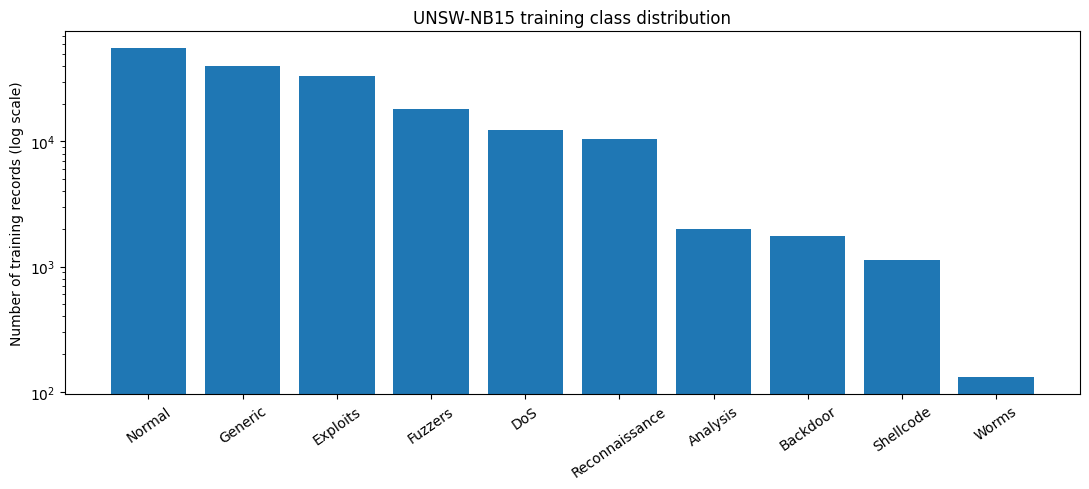

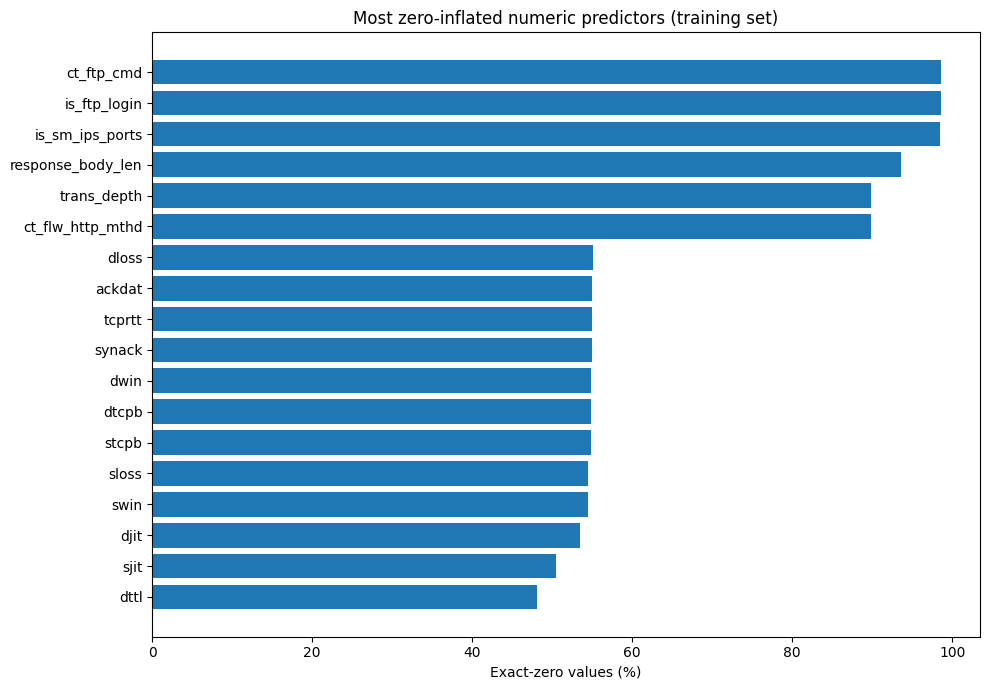

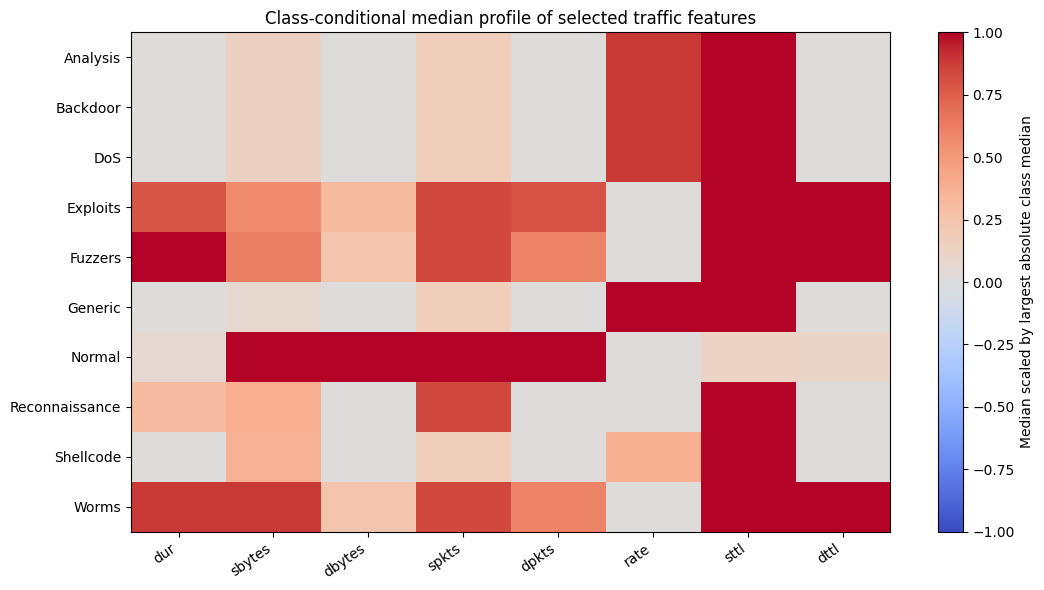

Class-wise median profile:


,dur,sbytes,dbytes,spkts,dpkts,rate,sttl,dttl
attack_cat,,,,,,,,
Analysis,0.000009,200.0,0.0,2.0,0.0,111111.107200,254.0,0.0
Backdoor,0.000009,200.0,0.0,2.0,0.0,111111.107200,254.0,0.0
DoS,0.000009,200.0,0.0,2.0,0.0,111111.107200,254.0,0.0
Exploits,0.486540,828.0,354.0,10.0,8.0,57.541243,254.0,252.0
Fuzzers,0.617445,914.0,268.0,10.0,6.0,32.341335,254.0,252.0
Generic,0.000008,114.0,0.0,2.0,0.0,125000.000300,254.0,0.0
Normal,0.038602,1470.0,1112.0,12.0,10.0,1382.256617,31.0,29.0
Reconnaissance,0.187315,564.0,0.0,10.0,0.0,78.970644,254.0,0.0
Shellcode,0.000021,536.0,0.0,2.0,0.0,47619.048000,254.0,0.0


High-correlation pairs are reported, not automatically deleted:


,feature_1,feature_2,spearman_correlation
17,is_ftp_login,ct_ftp_cmd,1.000000
16,trans_depth,ct_flw_http_mthd,0.999620
13,tcprtt,synack,0.996785
14,tcprtt,ackdat,0.993672
12,swin,dwin,0.990180
2,dpkts,dbytes,0.989853
15,synack,ackdat,0.984360
1,spkts,derived_total_packets,0.977452
0,dur,derived_packets_per_duration,-0.973455
5,sbytes,derived_total_bytes,0.964812


All training-only EDA outputs saved to: /content/Robust_NIDS_UNSW_NB15_F1_Analysis/results/metrics


In [5]:
# Training-only plots and class-conditional summaries.
class_plot = class_distribution.sort_values("count", ascending=False)
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(class_plot["attack_cat"], class_plot["count"])
ax.set_yscale("log")
ax.set_ylabel("Number of training records (log scale)")
ax.set_title("UNSW-NB15 training class distribution")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
CLASS_DISTRIBUTION_FIG = FIGURES_DIR / "training_class_distribution.png"
fig.savefig(CLASS_DISTRIBUTION_FIG, dpi=220, bbox_inches="tight")
plt.show()

zero_plot = feature_quality_report[
    feature_quality_report["feature_type"] == "numeric"
].sort_values("zero_percent", ascending=False).head(18).sort_values("zero_percent")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(zero_plot["feature"], zero_plot["zero_percent"])
ax.set_xlabel("Exact-zero values (%)")
ax.set_title("Most zero-inflated numeric predictors (training set)")
fig.tight_layout()
ZERO_INFLATION_FIG = FIGURES_DIR / "training_zero_inflation.png"
fig.savefig(ZERO_INFLATION_FIG, dpi=220, bbox_inches="tight")
plt.show()

profile_features = [c for c in ["dur", "sbytes", "dbytes", "spkts", "dpkts", "rate", "sttl", "dttl"] if c in numeric_columns]
class_numeric_profile = X_train_full.assign(attack_cat=y_train_full).groupby("attack_cat")[profile_features].median().reindex(classes)
class_numeric_profile.to_csv(METRICS_DIR / "class_numeric_median_profile.csv")
if profile_features:
    scaled_profile = class_numeric_profile.copy()
    for col in scaled_profile:
        denominator = max(float(scaled_profile[col].abs().max()), 1e-12)
        scaled_profile[col] = scaled_profile[col] / denominator
    fig, ax = plt.subplots(figsize=(11, 6))
    image = ax.imshow(scaled_profile.to_numpy(), aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
    fig.colorbar(image, ax=ax, label="Median scaled by largest absolute class median")
    ax.set_yticks(np.arange(len(classes)), labels=classes)
    ax.set_xticks(np.arange(len(profile_features)), labels=profile_features, rotation=35, ha="right")
    ax.set_title("Class-conditional median profile of selected traffic features")
    fig.tight_layout()
    CLASS_PROFILE_FIG = FIGURES_DIR / "training_class_feature_profile.png"
    fig.savefig(CLASS_PROFILE_FIG, dpi=220, bbox_inches="tight")
    plt.show()

print("Class-wise median profile:")
display(class_numeric_profile)
print("High-correlation pairs are reported, not automatically deleted:")
display(high_corr_df.head(25))
print("All training-only EDA outputs saved to:", METRICS_DIR)

## 4B. How to interpret the data audit

Review `data_audit.json`, `feature_quality_profile.csv`, `categorical_level_frequencies.csv`, `conflicting_duplicate_feature_groups.csv` and `high_correlation_pairs.csv` (raw plus engineered numeric inputs) and `high_correlation_pairs_raw_numeric_only.csv` (original numeric inputs only), `posthoc_test_feature_overlap_by_class.csv`, `posthoc_test_metrics_by_feature_overlap.csv` and the post-hoc test feature-profile files before interpreting model scores. In the supplied training partition, 74,301 rows repeat an existing raw feature vector; 1,772 feature groups contain conflicting `attack_cat` labels and cover 30,528 rows. These are dataset properties, not errors that can safely be removed without changing the benchmark. Grouped cross-validation keeps identical vectors together, but it cannot resolve contradictory labels for the same vector.

The class distribution is highly imbalanced: the largest class is about 431 times the smallest. `Worms` is especially rare, so accuracy alone is inadequate; inspect Macro-F1, balanced accuracy, per-class recall and support. Seventeen numerical predictors are at least 50% zero, and highly correlated feature pairs are reported but not automatically removed because they may carry useful traffic information.

The audit also checks record ordering. The `id` column has a strong association with the binary Normal/Attack indicator in this training partition; it is therefore excluded from model inputs. This is an audit warning about possible acquisition-order structure, not evidence that `id` should be used as a predictor.

The official test partition contains exact feature-vector matches with training rows. After the single final test evaluation, the notebook reports the overlap rate by actual class and compares performance on overlapping and non-overlapping test records. These are post-hoc dataset diagnostics only and must not be used to retune the model.

All feature statistics, preprocessing decisions and model selection are based on training data. The notebook reports outliers, missingness, correlation and zero inflation rather than automatically deleting records or features.


## 5. Fold-safe preprocessing and classifier pipelines

Numerical and categorical transformations are placed inside scikit-learn pipelines. Imputers, one-hot encoders and numerical transformations are fitted on each training fold only.

**S0:** raw numerical values after fold-fitted median imputation.  
**S1:** clip numerical features to the 1st–99th percentiles learned from the training fold.  
**S2:** signed-log transformation with zero indicators for sufficiently zero-heavy numerical columns.

The seven deterministic traffic-derived features use only original predictor values; no target or identifier is used.

### Lightweight replacement candidate

**LightGBM (Mild Weights)** replaces the previous slow learner. LightGBM uses histogram-based gradient boosting. The mild-weight configuration applies fractional inverse-frequency sample weights with exponent 0.35, normalized to a mean of one. This is less aggressive than full balanced weighting and is intended to improve minority-class F1 while limiting accuracy loss.


In [6]:
class NumericStrategy(BaseEstimator, TransformerMixin):
    """Fold-fitted raw, percentile clipping, or signed-log numeric transform."""
    def __init__(self, strategy="S0_Raw", zero_threshold=0.10):
        self.strategy = strategy
        self.zero_threshold = zero_threshold

    def _array(self, X):
        arr = np.asarray(X, dtype=np.float64)
        if arr.ndim == 1:
            arr = arr.reshape(-1, 1)
        arr = arr.copy()
        arr[~np.isfinite(arr)] = np.nan
        return arr

    def fit(self, X, y=None):
        arr = self._array(X)
        self.n_features_in_ = arr.shape[1]
        self.medians_ = np.zeros(self.n_features_in_, dtype=float)
        for j in range(self.n_features_in_):
            valid = arr[:, j][np.isfinite(arr[:, j])]
            self.medians_[j] = float(np.median(valid)) if len(valid) else 0.0
        filled = np.where(np.isfinite(arr), arr, self.medians_[None, :])
        self.lower_ = np.percentile(filled, 1, axis=0)
        self.upper_ = np.percentile(filled, 99, axis=0)
        self.zero_columns_ = np.mean(filled == 0, axis=0) >= self.zero_threshold
        return self

    def transform(self, X):
        arr = self._array(X)
        if arr.shape[1] != self.n_features_in_:
            raise ValueError("Numeric feature count changed after fit.")
        arr = np.where(np.isfinite(arr), arr, self.medians_[None, :])
        if self.strategy == "S0_Raw":
            return arr
        if self.strategy == "S1_Clipping":
            return np.clip(arr, self.lower_[None, :], self.upper_[None, :])
        if self.strategy == "S2_SignedLog":
            transformed = np.sign(arr) * np.log1p(np.abs(arr))
            if np.any(self.zero_columns_):
                indicators = (arr[:, self.zero_columns_] == 0).astype(float)
                transformed = np.hstack([transformed, indicators])
            return transformed
        raise ValueError(f"Unknown strategy: {self.strategy}")


class XGBMulticlassClassifier(ClassifierMixin, BaseEstimator):
    """sklearn-compatible XGBoost wrapper for string attack-category labels."""
    def __init__(self, n_estimators=400, max_depth=7, learning_rate=0.05,
                 subsample=0.90, colsample_bytree=0.90, min_child_weight=1,
                 reg_lambda=3.0, gamma=0.0, reg_alpha=0.0,
                 max_bin=256, random_state=42, n_jobs=4):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.min_child_weight = min_child_weight
        self.reg_lambda = reg_lambda
        self.gamma = gamma
        self.reg_alpha = reg_alpha
        self.max_bin = max_bin
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y, sample_weight=None):
        y_text = np.asarray(y).astype(str)
        self.label_encoder_ = LabelEncoder()
        y_encoded = self.label_encoder_.fit_transform(y_text)
        self.classes_ = self.label_encoder_.classes_
        self.n_classes_ = len(self.classes_)
        self.model_ = XGBClassifier(
            objective="multi:softprob", num_class=self.n_classes_,
            n_estimators=self.n_estimators, max_depth=self.max_depth,
            learning_rate=self.learning_rate, subsample=self.subsample,
            colsample_bytree=self.colsample_bytree,
            min_child_weight=self.min_child_weight, reg_lambda=self.reg_lambda,
            gamma=self.gamma, reg_alpha=self.reg_alpha, max_bin=self.max_bin,
            tree_method="hist", eval_metric="mlogloss", n_jobs=self.n_jobs,
            random_state=self.random_state
        )
        fit_kwargs = {}
        if sample_weight is not None:
            fit_kwargs["sample_weight"] = sample_weight
        self.model_.fit(X, y_encoded, **fit_kwargs)
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        encoded = self.model_.predict(X).astype(int)
        return self.label_encoder_.inverse_transform(encoded)

    def predict_proba(self, X):
        return self.model_.predict_proba(X)


class LightGBMXGBSoftVotingClassifier(ClassifierMixin, BaseEstimator):
    """Unweighted soft-voting blend with shared label encoding and aligned classes."""
    def __init__(self, random_state=42, n_jobs=4, fast_screen=False):
        self.random_state = random_state
        self.n_jobs = n_jobs
        self.fast_screen = fast_screen

    def fit(self, X, y, sample_weight=None):
        y_text = np.asarray(y).astype(str)
        self.label_encoder_ = LabelEncoder()
        y_encoded = self.label_encoder_.fit_transform(y_text)
        self.classes_ = self.label_encoder_.classes_
        n_classes = len(self.classes_)
        if self.fast_screen:
            lgb_trees, xgb_trees = 120, 120
            leaves, depth = 31, 6
        else:
            lgb_trees, xgb_trees = 550, 500
            leaves, depth = 63, 7
        self.lgbm_ = LGBMClassifier(
            objective="multiclass", n_estimators=lgb_trees,
            learning_rate=0.05 if self.fast_screen else 0.035,
            num_leaves=leaves, max_depth=-1, min_child_samples=40,
            subsample=0.90, subsample_freq=1, colsample_bytree=0.90,
            reg_lambda=3.0, class_weight=None, n_jobs=self.n_jobs,
            random_state=self.random_state, verbosity=-1
        )
        self.xgb_ = XGBClassifier(
            objective="multi:softprob", num_class=n_classes,
            n_estimators=xgb_trees, max_depth=depth,
            learning_rate=0.06 if self.fast_screen else 0.04,
            subsample=0.90, colsample_bytree=0.90, min_child_weight=2,
            reg_lambda=3.0, tree_method="hist", eval_metric="mlogloss",
            n_jobs=self.n_jobs, random_state=self.random_state
        )
        fit_kwargs = {}
        if sample_weight is not None:
            fit_kwargs["sample_weight"] = sample_weight
        self.lgbm_.fit(X, y_encoded, **fit_kwargs)
        self.xgb_.fit(X, y_encoded, **fit_kwargs)
        self.n_features_in_ = X.shape[1]
        return self

    def predict_proba(self, X):
        p_lgbm = self.lgbm_.predict_proba(X)
        p_xgb = self.xgb_.predict_proba(X)
        probabilities = 0.5 * p_lgbm + 0.5 * p_xgb
        probabilities = np.clip(probabilities, 1e-12, 1.0)
        return probabilities / probabilities.sum(axis=1, keepdims=True)

    def predict(self, X):
        encoded = np.argmax(self.predict_proba(X), axis=1)
        return self.label_encoder_.inverse_transform(encoded)


def compute_mild_class_weights(y, exponent=MILD_CLASS_WEIGHT_EXPONENT):
    """Fractional inverse-frequency weights, normalized to mean one."""
    y_series = pd.Series(np.asarray(y).astype(str))
    counts = y_series.value_counts()
    inverse_frequency = len(y_series) / (len(counts) * counts)
    class_weights = inverse_frequency.astype(float) ** float(exponent)
    weights = y_series.map(class_weights).to_numpy(dtype=float)
    weights /= max(float(weights.mean()), 1e-12)
    return weights


def build_pipeline(model_name, strategy, numeric_cols=None, categorical_cols=None, fast_screen=False):
    numeric_cols = list(numeric_columns if numeric_cols is None else numeric_cols)
    categorical_cols = list(categorical_columns if categorical_cols is None else categorical_cols)

    transformers = []
    if numeric_cols:
        numeric_steps = [("strategy", NumericStrategy(strategy=strategy))]
        if model_name == "Logistic Regression":
            numeric_steps.append(("scaler", StandardScaler()))
        transformers.append(("numeric", Pipeline(numeric_steps), numeric_cols))

    if categorical_cols:
        use_sparse = model_name != "HistGradientBoosting"
        category_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=use_sparse))
        ])
        transformers.append(("categorical", category_pipeline, categorical_cols))

    preprocessing = ColumnTransformer(
        transformers=transformers, remainder="drop",
        sparse_threshold=0.0 if model_name == "HistGradientBoosting" else 0.3
    )

    if model_name == "Logistic Regression":
        classifier = LogisticRegression(
            solver="saga", C=1.0, max_iter=LOGISTIC_MAX_ITER,
            tol=1e-3, class_weight="balanced", random_state=RANDOM_STATE
        )
    elif model_name == "Random Forest (Balanced)":
        classifier = RandomForestClassifier(
            n_estimators=80 if fast_screen else 160,
            max_depth=18 if fast_screen else 24, min_samples_leaf=2,
            max_features="sqrt", class_weight="balanced_subsample",
            random_state=RANDOM_STATE, n_jobs=-1
        )
    elif model_name == "Random Forest (Unweighted)":
        classifier = RandomForestClassifier(
            n_estimators=100 if fast_screen else RF_TREES,
            max_depth=20 if fast_screen else None,
            min_samples_leaf=2 if fast_screen else 1,
            max_features="sqrt", class_weight=None,
            random_state=RANDOM_STATE, n_jobs=-1
        )
    elif model_name == "ExtraTrees":
        classifier = ExtraTreesClassifier(
            n_estimators=80 if fast_screen else EXTRA_TREES,
            max_depth=22 if fast_screen else None, min_samples_leaf=2 if fast_screen else 1,
            max_features="sqrt", class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1
        )
    elif model_name == "ExtraTrees (Unweighted)":
        classifier = ExtraTreesClassifier(
            n_estimators=100 if fast_screen else 350,
            max_depth=None, min_samples_leaf=1,
            max_features=0.80, class_weight=None,
            random_state=RANDOM_STATE + 11, n_jobs=-1
        )
    elif model_name == "HistGradientBoosting":
        classifier = HistGradientBoostingClassifier(
            max_iter=55 if fast_screen else HGB_ITERATIONS, learning_rate=0.08,
            max_leaf_nodes=23 if fast_screen else 31, l2_regularization=1.0,
            early_stopping=True, random_state=RANDOM_STATE
        )
    elif model_name == "LightGBM (Balanced)":
        classifier = LGBMClassifier(
            objective="multiclass", n_estimators=260, learning_rate=0.05,
            num_leaves=31, min_child_samples=30, subsample=0.85,
            subsample_freq=1, colsample_bytree=0.90, reg_lambda=2.0,
            class_weight="balanced", n_jobs=-1,
            random_state=RANDOM_STATE, verbosity=-1
        )
    elif model_name == "LightGBM (Unweighted)":
        classifier = LGBMClassifier(
            objective="multiclass", n_estimators=160 if fast_screen else LIGHTGBM_TREES,
            learning_rate=0.05 if fast_screen else 0.035,
            num_leaves=31 if fast_screen else 63, max_depth=-1,
            min_child_samples=45 if fast_screen else 40,
            subsample=0.90, subsample_freq=1,
            colsample_bytree=0.90, reg_lambda=3.0, class_weight=None,
            n_jobs=-1, random_state=RANDOM_STATE, verbosity=-1
        )
    elif model_name == "LightGBM (Mild Weights)":
        classifier = LGBMClassifier(
            objective="multiclass", n_estimators=150 if fast_screen else 520,
            learning_rate=0.05 if fast_screen else 0.035,
            num_leaves=31 if fast_screen else 47, max_depth=-1,
            min_child_samples=50 if fast_screen else 45,
            subsample=0.90, subsample_freq=1, colsample_bytree=0.90,
            reg_lambda=4.0, class_weight=None, n_jobs=-1,
            random_state=RANDOM_STATE, verbosity=-1
        )
    elif model_name == "LightGBM (Regularized)":
        # Higher-capacity unweighted LightGBM configuration; selected only on grouped validation.
        classifier = LGBMClassifier(
            objective="multiclass", n_estimators=220 if fast_screen else 750,
            learning_rate=0.045 if fast_screen else 0.032,
            num_leaves=63, max_depth=-1,
            min_child_samples=35 if fast_screen else 40,
            subsample=0.90, subsample_freq=1,
            colsample_bytree=0.95, reg_lambda=3.5,
            reg_alpha=0.05, class_weight=None,
            n_jobs=-1, random_state=RANDOM_STATE + 17, verbosity=-1
        )
    elif model_name == "XGBoost (Balanced)":
        classifier = XGBMulticlassClassifier(
            n_estimators=100 if fast_screen else 220,
            max_depth=5 if fast_screen else 7,
            learning_rate=0.09 if fast_screen else 0.07,
            subsample=0.85, colsample_bytree=0.85, min_child_weight=2,
            reg_lambda=2.0, random_state=RANDOM_STATE, n_jobs=4
        )
    elif model_name == "XGBoost (Unweighted)":
        classifier = XGBMulticlassClassifier(
            n_estimators=160 if fast_screen else XGBOOST_TREES,
            max_depth=6 if fast_screen else 7,
            learning_rate=0.06 if fast_screen else 0.045,
            subsample=0.90, colsample_bytree=0.90, min_child_weight=2,
            reg_lambda=3.0, gamma=0.0, reg_alpha=0.0,
            random_state=RANDOM_STATE, n_jobs=4
        )
    elif model_name == "XGBoost (Mild Weights)":
        classifier = XGBMulticlassClassifier(
            n_estimators=150 if fast_screen else XGBOOST_TREES,
            max_depth=6 if fast_screen else 7,
            learning_rate=0.06 if fast_screen else 0.045,
            subsample=0.90, colsample_bytree=0.90, min_child_weight=2,
            reg_lambda=3.0, random_state=RANDOM_STATE, n_jobs=4
        )
    elif model_name == "XGBoost (Regularized)":
        # More conservative regularization and additional boosting rounds to reduce under/overfitting.
        classifier = XGBMulticlassClassifier(
            n_estimators=200 if fast_screen else 650,
            max_depth=6, learning_rate=0.055 if fast_screen else 0.038,
            subsample=0.92, colsample_bytree=0.95,
            min_child_weight=2, reg_lambda=4.0,
            gamma=0.02, reg_alpha=0.05, max_bin=256,
            random_state=RANDOM_STATE + 23, n_jobs=4
        )
    elif model_name == "Soft Voting (Unweighted)":
        classifier = LightGBMXGBSoftVotingClassifier(
            random_state=RANDOM_STATE + 29, n_jobs=4, fast_screen=fast_screen
        )
    else:
        raise ValueError(f"Unsupported candidate model: {model_name}")

    return Pipeline([("preprocessing", preprocessing), ("classifier", classifier)])


def fit_candidate(model, model_name, X, y):
    if model_name in {"XGBoost (Balanced)", "HistGradientBoosting"}:
        weights = compute_sample_weight(class_weight="balanced", y=y)
        model.fit(X, y, classifier__sample_weight=weights)
    elif model_name in {"XGBoost (Mild Weights)", "LightGBM (Mild Weights)"}:
        weights = compute_mild_class_weights(y)
        model.fit(X, y, classifier__sample_weight=weights)
    else:
        # Accuracy-oriented unweighted candidates do not use class reweighting.
        model.fit(X, y)
    return model


## 6. Evaluation metrics

Multiclass false-positive rate is calculated one-vs-rest for each class: `FP / (FP + TN)`. Macro FPR is the unweighted mean across classes. A separate binary Normal-versus-Attack FPR is also calculated, with Normal as the negative class.

In [7]:
def align_model_probabilities(model, X, labels):
    """Align classifier probability columns with the canonical training-label order."""
    raw_prob = np.asarray(model.predict_proba(X), dtype=float)
    estimator = model.named_steps["classifier"] if hasattr(model, "named_steps") else model
    model_classes = [str(v) for v in getattr(estimator, "classes_")]
    aligned = np.zeros((len(X), len(labels)), dtype=float)
    label_positions = {str(label): i for i, label in enumerate(labels)}
    for source_index, class_name in enumerate(model_classes):
        if class_name in label_positions:
            aligned[:, label_positions[class_name]] = raw_prob[:, source_index]
    row_sums = aligned.sum(axis=1, keepdims=True)
    aligned = np.divide(aligned, row_sums, out=np.zeros_like(aligned), where=row_sums > 0)
    return aligned


def calculate_metrics(y_true, y_pred, labels, y_proba=None):
    y_true = np.asarray(y_true).astype(str)
    y_pred = np.asarray(y_pred).astype(str)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, zero_division=0
    )
    p_weighted, r_weighted, f_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    total = int(cm.sum())
    per_class_rows = []
    for i, label in enumerate(labels):
        tp = int(cm[i, i])
        fp = int(cm[:, i].sum() - tp)
        fn = int(cm[i, :].sum() - tp)
        tn = total - tp - fp - fn
        fpr = fp / (fp + tn) if (fp + tn) else 0.0
        specificity = tn / (tn + fp) if (tn + fp) else 0.0
        per_class_rows.append({
            "class": str(label), "precision": float(precision[i]),
            "recall": float(recall[i]), "f1_score": float(f1[i]),
            "specificity": float(specificity),
            "false_positive_rate_ovr": float(fpr), "support": int(support[i])
        })

    normal_label = "Normal" if "Normal" in labels else None
    if normal_label is not None:
        true_attack = y_true != normal_label
        predicted_attack = y_pred != normal_label
        fp_attack = int(np.sum(~true_attack & predicted_attack))
        fn_attack = int(np.sum(true_attack & ~predicted_attack))
        tn_attack = int(np.sum(~true_attack & ~predicted_attack))
        tp_attack = int(np.sum(true_attack & predicted_attack))
        binary_fpr = fp_attack / (fp_attack + tn_attack) if (fp_attack + tn_attack) else 0.0
        attack_recall = tp_attack / (tp_attack + fn_attack) if (tp_attack + fn_attack) else 0.0
    else:
        binary_fpr, attack_recall = float("nan"), float("nan")

    summary = {
        "n_samples": total,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(np.mean(recall)),
        "precision_macro": float(np.mean(precision)),
        "recall_macro": float(np.mean(recall)),
        "f1_macro": float(np.mean(f1)),
        "precision_weighted": float(p_weighted),
        "recall_weighted": float(r_weighted),
        "f1_weighted": float(f_weighted),
        "fpr_macro_ovr": float(np.mean([r["false_positive_rate_ovr"] for r in per_class_rows])),
        "specificity_macro_ovr": float(np.mean([r["specificity"] for r in per_class_rows])),
        "normal_vs_attack_fpr": float(binary_fpr),
        "attack_detection_recall": float(attack_recall),
        "matthews_corrcoef": float(matthews_corrcoef(y_true, y_pred))
    }

    if y_proba is not None:
        probabilities = np.asarray(y_proba, dtype=float)
        if probabilities.shape != (len(y_true), len(labels)):
            raise ValueError(f"Probability matrix shape {probabilities.shape} does not match {(len(y_true), len(labels))}.")
        probabilities = np.clip(probabilities, 1e-12, 1.0)
        probabilities = probabilities / probabilities.sum(axis=1, keepdims=True)
        y_onehot = np.column_stack([y_true == label for label in labels]).astype(float)
        summary["log_loss"] = float(log_loss(y_true, probabilities, labels=labels))
        summary["brier_score_multiclass"] = float(np.mean(np.sum((probabilities - y_onehot) ** 2, axis=1)))
        try:
            summary["roc_auc_macro_ovr"] = float(roc_auc_score(
                y_true, probabilities, labels=labels, multi_class="ovr", average="macro"
            ))
        except Exception:
            summary["roc_auc_macro_ovr"] = float("nan")
        try:
            summary["average_precision_macro_ovr"] = float(average_precision_score(
                y_onehot, probabilities, average="macro"
            ))
        except Exception:
            summary["average_precision_macro_ovr"] = float("nan")
        if len(labels) >= 2:
            top2_indices = np.argpartition(probabilities, -2, axis=1)[:, -2:]
            true_index = {label: i for i, label in enumerate(labels)}
            summary["top2_accuracy"] = float(np.mean([
                true_index[label] in top2_indices[row]
                for row, label in enumerate(y_true)
            ]))

    return summary, pd.DataFrame(per_class_rows), cm


def risk_level(category):
    return "Normal" if str(category).strip().lower() == "normal" else "Attack"

## 7. Fast duplicate-aware model screening

**FAST_MODE=True is the default.** Nine candidate configurations are evaluated across two duplicate-grouped folds. Each fold is formed before sampling, and the screening sample is drawn by complete feature-hash groups (approximately 20% of groups per class, with a minimum of 20 groups where available). This prevents exact feature groups from crossing the training/validation boundary.

The comparison includes Random Forest, ExtraTrees, unweighted and class-weighted LightGBM, unweighted and class-weighted XGBoost, tuned gradient-boosting configurations and a soft-voting ensemble. Screening uses reduced estimator counts. It is intended to identify promising configurations quickly, not to replace the full validation protocol.

The selection rule reports multiple measures and maximizes Macro-F1 among candidates whose mean validation accuracy is within 1.5 percentage points of the best screened accuracy. This keeps overall accuracy visible while considering recall and F1 across all ten categories. The final selected estimator is refitted on the complete training partition. Set `FAST_MODE=False` for the longer grouped confirmation and preprocessing study. The official test partition is not used for selection.

In [8]:
# Duplicate-aware folds are created from the training partition only.
# FAST_MODE evaluates the candidate set on two sampled duplicate-grouped folds.
# FAST_MODE=False restores the longer full-data screen and five-fold confirmation.
splitter = StratifiedGroupKFold(
    n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE
)
folds = list(splitter.split(X_train, y_train, groups))

base_screen_splits = 2 if FAST_MODE else SCREEN_SPLITS
screen_splitter = StratifiedGroupKFold(
    n_splits=base_screen_splits, shuffle=True, random_state=RANDOM_STATE + 101
)
base_screen_folds = list(screen_splitter.split(X_train, y_train, groups))


def sample_group_preserving_indices(indices, fraction, seed, min_groups_per_class=20):
    """Sample complete duplicate-feature groups and keep every target class represented."""
    local_y = y_train.iloc[indices].astype(str).to_numpy()
    local_groups = groups[indices]
    group_to_labels = {}
    for group_value, label in zip(local_groups, local_y):
        group_to_labels.setdefault(int(group_value), set()).add(str(label))

    rng = np.random.default_rng(seed)
    selected_groups = set()
    report_rows = []
    for class_name in classes:
        candidate_groups = [
            group_value for group_value, labels_in_group in group_to_labels.items()
            if class_name in labels_in_group
        ]
        if not candidate_groups:
            raise RuntimeError(f"Class {class_name!r} has no feature groups in this fold.")
        take = min(
            len(candidate_groups),
            max(int(min_groups_per_class), int(math.ceil(len(candidate_groups) * fraction)))
        )
        chosen = rng.choice(len(candidate_groups), size=take, replace=False)
        chosen_groups = [candidate_groups[int(pos)] for pos in chosen]
        selected_groups.update(chosen_groups)
        report_rows.append({
            "class": class_name,
            "available_groups": len(candidate_groups),
            "sampled_groups": len(chosen_groups)
        })

    keep_mask = np.fromiter(
        (int(group_value) in selected_groups for group_value in local_groups),
        dtype=bool, count=len(local_groups)
    )
    sampled_indices = np.asarray(indices, dtype=int)[keep_mask]
    missing = set(classes) - set(y_train.iloc[sampled_indices].astype(str))
    if missing:
        raise RuntimeError(f"Grouped screen sample is missing classes: {sorted(missing)}")
    return np.sort(sampled_indices), report_rows


if FAST_MODE:
    # Sample each side of both group folds independently. The SGKF split happens
    # before sampling, so no exact feature-hash group can cross a fold boundary.
    screen_folds = []
    screen_sample_rows = []
    for fold_no, (base_train_idx, base_valid_idx) in enumerate(base_screen_folds, start=1):
        sampled_train, train_sample_info = sample_group_preserving_indices(
            base_train_idx, FAST_SCREEN_GROUP_FRACTION,
            RANDOM_STATE + 200 + fold_no * 2, FAST_SCREEN_MIN_GROUPS_PER_CLASS
        )
        sampled_valid, valid_sample_info = sample_group_preserving_indices(
            base_valid_idx, FAST_SCREEN_GROUP_FRACTION,
            RANDOM_STATE + 201 + fold_no * 2, FAST_SCREEN_MIN_GROUPS_PER_CLASS
        )
        screen_folds.append((sampled_train, sampled_valid))
        screen_sample_rows.extend([
            {"fold": fold_no, "partition": "train", **r} for r in train_sample_info
        ])
        screen_sample_rows.extend([
            {"fold": fold_no, "partition": "validation", **r} for r in valid_sample_info
        ])
    pd.DataFrame(screen_sample_rows).to_csv(
        METRICS_DIR / "fast_screen_group_sample.csv", index=False
    )
else:
    screen_folds = base_screen_folds

if len(folds) != N_SPLITS or len(screen_folds) != SCREEN_SPLITS:
    raise RuntimeError("Grouped cross-validation folds were not created as expected.")

for split_name, split_list in [("screen", screen_folds), ("diagnostic", folds)]:
    for fold_number, (train_idx, valid_idx) in enumerate(split_list, start=1):
        overlap = set(groups[train_idx]).intersection(set(groups[valid_idx]))
        if overlap:
            raise AssertionError(f"Duplicate-group leakage detected in {split_name} fold {fold_number}.")
        train_classes = set(y_train.iloc[train_idx].astype(str))
        valid_classes = set(y_train.iloc[valid_idx].astype(str))
        if train_classes != set(classes) or valid_classes != set(classes):
            raise AssertionError(
                f"Class coverage failure in {split_name} fold {fold_number}. "
                f"Train missing={set(classes)-train_classes}; validation missing={set(classes)-valid_classes}"
            )

fold_coverage_rows = []
for fold_number, (train_idx, valid_idx) in enumerate(folds, start=1):
    fold_coverage_rows.append({
        "fold": fold_number,
        "train_rows": len(train_idx),
        "validation_rows": len(valid_idx),
        "train_classes_present": len(set(y_train.iloc[train_idx])),
        "validation_classes_present": len(set(y_train.iloc[valid_idx])),
        "train_worms": int((y_train.iloc[train_idx] == "Worms").sum()),
        "validation_worms": int((y_train.iloc[valid_idx] == "Worms").sum()),
        "duplicate_groups_crossing_fold": 0
    })
pd.DataFrame(fold_coverage_rows).to_csv(METRICS_DIR / "grouped_fold_coverage.csv", index=False)


def run_cv_configuration(model_name, strategy, folds_to_use, stage_name):
    rows = []
    for fold_number, (train_idx, valid_idx) in enumerate(folds_to_use, start=1):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_valid = X_train.iloc[valid_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_valid = y_train.iloc[valid_idx]

        print(
            f"Starting {model_name} | {stage_name} | fold {fold_number}/{len(folds_to_use)} | "
            f"train_rows={len(train_idx):,} | validation_rows={len(valid_idx):,} | "
            f"reduced_estimators={FAST_MODE}", flush=True
        )
        start = time.perf_counter()
        if model_name == "Majority Classifier":
            model = DummyClassifier(strategy="most_frequent")
            model.fit(X_fold_train, y_fold_train)
        else:
            model = build_pipeline(model_name, strategy, fast_screen=FAST_MODE)
            fit_candidate(model, model_name, X_fold_train, y_fold_train)
        fit_seconds = time.perf_counter() - start

        prediction_start = time.perf_counter()
        predictions = model.predict(X_fold_valid)
        prediction_seconds = time.perf_counter() - prediction_start
        probabilities = align_model_probabilities(model, X_fold_valid, classes)
        metrics, _, _ = calculate_metrics(
            y_fold_valid.to_numpy(), predictions, classes, probabilities
        )
        rows.append({
            "stage": stage_name,
            "model": model_name,
            "preprocessing": strategy,
            "fold": fold_number,
            "train_rows": int(len(train_idx)),
            "validation_rows": int(len(valid_idx)),
            "fast_estimator_proxy": bool(FAST_MODE),
            **metrics,
            "fit_seconds": float(fit_seconds),
            "predict_seconds": float(prediction_seconds)
        })
        print(
            f"{stage_name} | {model_name} | fold {fold_number}/{len(folds_to_use)} | "
            f"Accuracy={metrics['accuracy']:.4f} | Macro-Recall={metrics['recall_macro']:.4f} | "
            f"Macro-F1={metrics['f1_macro']:.4f} | Weighted-F1={metrics['f1_weighted']:.4f} | "
            f"fit={fit_seconds:.1f}s", flush=True
        )
        del model, predictions, probabilities
        gc.collect()
    return rows


def rank_results(frame, metric=SELECTION_METRIC):
    summary = frame.groupby("model").agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        macro_precision_mean=("precision_macro", "mean"),
        macro_recall_mean=("recall_macro", "mean"),
        macro_f1_mean=("f1_macro", "mean"),
        macro_f1_std=("f1_macro", "std"),
        weighted_f1_mean=("f1_weighted", "mean"),
        macro_fpr_mean=("fpr_macro_ovr", "mean")
    ).reset_index()
    # Rank the screen by Macro-F1, then recall and accuracy. Final selection
    # applies the explicit accuracy guardrail in the next section.
    return summary.sort_values(
        ["macro_f1_mean", "macro_recall_mean", "accuracy_mean", "macro_fpr_mean"],
        ascending=[False, False, False, True]
    ).reset_index(drop=True)


planned_fits = (len(ACTIVE_CANDIDATE_MODELS) + 1) * SCREEN_SPLITS
print(
    f"FAST MODEL COMPARISON: {len(ACTIVE_CANDIDATE_MODELS)} models + majority baseline "
    f"across {SCREEN_SPLITS} sampled grouped folds = {planned_fits} short fits.",
    flush=True
)
if FAST_MODE:
    for fold_no, (tr_idx, va_idx) in enumerate(screen_folds, start=1):
        print(
            f"Fold {fold_no}: {len(tr_idx):,} sampled train rows / "
            f"{len(va_idx):,} sampled validation rows (full fold: "
            f"{len(folds[fold_no-1][0]):,}/{len(folds[fold_no-1][1]):,}).",
            flush=True
        )
    print("All active candidates use reduced tree counts. The final selected model is refitted once on the full training set with full settings.", flush=True)

screen_rows = []
screen_rows.extend(run_cv_configuration(
    "Majority Classifier", "N/A", screen_folds,
    "fast sampled grouped screening" if FAST_MODE else "grouped screening"
))
for model_name in ACTIVE_CANDIDATE_MODELS:
    print(f"\n===== Screening: {model_name} / S0_Raw =====", flush=True)
    screen_rows.extend(run_cv_configuration(
        model_name, "S0_Raw", screen_folds,
        "fast sampled grouped screening" if FAST_MODE else "grouped screening"
    ))

screen_results = pd.DataFrame(screen_rows)
screen_results.to_csv(METRICS_DIR / "grouped_model_screening.csv", index=False)
screen_summary = rank_results(
    screen_results[screen_results["model"] != "Majority Classifier"]
)
screen_summary.to_csv(METRICS_DIR / "grouped_screening_summary.csv", index=False)

if FAST_MODE:
    # Keep the two leading candidates and force-retain the prior best-accuracy
    # reference so the new candidates are compared against unweighted XGBoost.
    TOP_MODELS = screen_summary.head(2)["model"].tolist()
    if "XGBoost (Unweighted)" not in TOP_MODELS:
        TOP_MODELS[-1] = "XGBoost (Unweighted)"
    PREPROCESSING_MODELS = []
    cv_fold_results = screen_results.copy()
    VALIDATION_RESULTS_PATH = METRICS_DIR / "fast_grouped_model_selection_results.csv"
    print("Fast-screen candidates for review:", TOP_MODELS, flush=True)
else:
    # Full research mode retains separate five-fold confirmation and S1/S2 studies.
    TOP_MODELS = screen_summary.head(SCREENING_FINALISTS)["model"].tolist()
    for required_model in ["XGBoost (Unweighted)", "LightGBM (Mild Weights)"]:
        if required_model in ACTIVE_CANDIDATE_MODELS and required_model not in TOP_MODELS:
            TOP_MODELS.append(required_model)
    cv_rows = []
    cv_rows.extend(run_cv_configuration("Majority Classifier", "N/A", folds, "five-fold confirmation"))
    for model_name in TOP_MODELS:
        cv_rows.extend(run_cv_configuration(model_name, "S0_Raw", folds, "five-fold confirmation"))
    final_s0 = pd.DataFrame([r for r in cv_rows if r["preprocessing"] == "S0_Raw"])
    final_s0_learned = final_s0[final_s0["model"] != "Majority Classifier"]
    final_s0_summary = rank_results(final_s0_learned)
    PREPROCESSING_MODELS = final_s0_summary["model"].tolist()[:PREPROCESSING_FINALISTS]
    for model_name in PREPROCESSING_MODELS:
        for strategy in ["S1_Clipping", "S2_SignedLog"]:
            cv_rows.extend(run_cv_configuration(model_name, strategy, folds, "five-fold confirmation"))
    cv_fold_results = pd.DataFrame(cv_rows)
    VALIDATION_RESULTS_PATH = METRICS_DIR / "five_fold_results.csv"

cv_fold_results.to_csv(VALIDATION_RESULTS_PATH, index=False)
fold_counts = cv_fold_results.groupby(["model", "preprocessing"]).size()
expected_validation_folds = SCREEN_SPLITS if FAST_MODE else N_SPLITS
if not (fold_counts == expected_validation_folds).all():
    raise AssertionError(f"Every evaluated configuration must contain {expected_validation_folds} folds.")

summary_rows = []
for (model_name, strategy), group in cv_fold_results.groupby(
    ["model", "preprocessing"], dropna=False
):
    summary_rows.append({
        "model": model_name,
        "preprocessing": strategy,
        "fold_accuracy_mean": float(group["accuracy"].mean()),
        "fold_accuracy_std": float(group["accuracy"].std(ddof=1)) if len(group) > 1 else 0.0,
        "fold_balanced_accuracy_mean": float(group["balanced_accuracy"].mean()),
        "fold_precision_macro_mean": float(group["precision_macro"].mean()),
        "fold_recall_macro_mean": float(group["recall_macro"].mean()),
        "fold_macro_f1_mean": float(group["f1_macro"].mean()),
        "fold_macro_f1_std": float(group["f1_macro"].std(ddof=1)) if len(group) > 1 else 0.0,
        "fold_weighted_f1_mean": float(group["f1_weighted"].mean()),
        "fold_macro_fpr_mean": float(group["fpr_macro_ovr"].mean()),
        "mean_fit_seconds": float(group["fit_seconds"].mean()),
        "mean_predict_seconds": float(group["predict_seconds"].mean()),
        "validation_rows_mean": float(group["validation_rows"].mean()),
        "fast_estimator_proxy": bool(group["fast_estimator_proxy"].all())
    })
cv_summary = pd.DataFrame(summary_rows)
primary_col = "fold_accuracy_mean" if SELECTION_METRIC == "accuracy" else "fold_macro_f1_mean"
secondary_col = "fold_macro_f1_mean" if SELECTION_METRIC == "accuracy" else "fold_accuracy_mean"
cv_summary = cv_summary.sort_values(
    [primary_col, secondary_col, "fold_macro_fpr_mean"],
    ascending=[False, False, True]
).reset_index(drop=True)
cv_summary.to_csv(METRICS_DIR / "model_comparison_summary.csv", index=False)
# A compact view of the main operating metrics for easy review.
performance_view = cv_summary[[
    "model", "fold_accuracy_mean", "fold_balanced_accuracy_mean",
    "fold_precision_macro_mean", "fold_recall_macro_mean",
    "fold_macro_f1_mean", "fold_weighted_f1_mean",
    "fold_macro_fpr_mean", "mean_fit_seconds"
]].copy()
performance_view.to_csv(METRICS_DIR / "screening_performance_summary.csv", index=False)
print("\nGrouped model comparison (accuracy, precision, recall, F1 and runtime):")
display(performance_view)


FAST MODEL COMPARISON: 9 models + majority baseline across 2 sampled grouped folds = 20 short fits.
Fold 1: 25,708 sampled train rows / 25,304 sampled validation rows (full fold: 88,082/87,259).
Fold 2: 25,596 sampled train rows / 25,619 sampled validation rows (full fold: 87,259/88,082).
All active candidates use reduced tree counts. The final selected model is refitted once on the full training set with full settings.
Starting Majority Classifier | fast sampled grouped screening | fold 1/2 | train_rows=25,708 | validation_rows=25,304 | reduced_estimators=True
fast sampled grouped screening | Majority Classifier | fold 1/2 | Accuracy=0.2619 | Macro-Recall=0.1000 | Macro-F1=0.0415 | Weighted-F1=0.1087 | fit=0.0s
Starting Majority Classifier | fast sampled grouped screening | fold 2/2 | train_rows=25,596 | validation_rows=25,619 | reduced_estimators=True
fast sampled grouped screening | Majority Classifier | fold 2/2 | Accuracy=0.2707 | Macro-Recall=0.1000 | Macro-F1=0.0426 | Weighted-F

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


fast sampled grouped screening | LightGBM (Unweighted) | fold 1/2 | Accuracy=0.7142 | Macro-Recall=0.5052 | Macro-F1=0.5276 | Weighted-F1=0.6699 | fit=11.4s
Starting LightGBM (Unweighted) | fast sampled grouped screening | fold 2/2 | train_rows=25,596 | validation_rows=25,619 | reduced_estimators=True


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


fast sampled grouped screening | LightGBM (Unweighted) | fold 2/2 | Accuracy=0.6990 | Macro-Recall=0.4821 | Macro-F1=0.4961 | Weighted-F1=0.6493 | fit=10.9s

===== Screening: LightGBM (Regularized) / S0_Raw =====
Starting LightGBM (Regularized) | fast sampled grouped screening | fold 1/2 | train_rows=25,708 | validation_rows=25,304 | reduced_estimators=True


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (8 outputs left out)

fast sampled grouped screening | Soft Voting (Unweighted) | fold 1/2 | Accuracy=0.7128 | Macro-Recall=0.5120 | Macro-F1=0.5292 | Weighted-F1=0.6561 | fit=25.3s
Starting Soft Voting (Unweighted) | fast sampled grouped screening | fold 2/2 | train_rows=25,596 | validation_rows=25,619 | reduced_estimators=True


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


fast sampled grouped screening | Soft Voting (Unweighted) | fold 2/2 | Accuracy=0.7008 | Macro-Recall=0.4751 | Macro-F1=0.4807 | Weighted-F1=0.6379 | fit=22.5s
Fast-screen candidates for review: ['LightGBM (Mild Weights)', 'XGBoost (Unweighted)']

Grouped model comparison (accuracy, precision, recall, F1 and runtime):


,model,fold_accuracy_mean,fold_balanced_accuracy_mean,fold_precision_macro_mean,fold_recall_macro_mean,fold_macro_f1_mean,fold_weighted_f1_mean,fold_macro_fpr_mean,mean_fit_seconds
0,LightGBM (Mild Weights),0.700856,0.538700,0.658486,0.538700,0.555786,0.692459,0.037872,10.731212
1,XGBoost (Mild Weights),0.701132,0.543163,0.666215,0.543163,0.553137,0.690106,0.037981,14.081818
2,LightGBM (Regularized),0.704997,0.502992,0.683210,0.502992,0.525783,0.672118,0.038615,22.935535
3,ExtraTrees (Unweighted),0.703877,0.499883,0.603732,0.499883,0.523171,0.679628,0.038340,90.669799
4,XGBoost (Unweighted),0.706731,0.496790,0.714177,0.496790,0.511964,0.647146,0.039020,15.462092
5,LightGBM (Unweighted),0.706624,0.493667,0.697058,0.493667,0.511862,0.659632,0.038818,11.145061
6,XGBoost (Regularized),0.706965,0.493290,0.714466,0.493290,0.508618,0.647421,0.038988,19.354469
7,Soft Voting (Unweighted),0.706771,0.493557,0.710359,0.493557,0.504955,0.647002,0.039020,23.886484
8,Random Forest (Unweighted),0.703757,0.440977,0.597384,0.440977,0.448654,0.650269,0.039221,15.983075
9,Majority Classifier,0.266296,0.100000,0.026630,0.100000,0.042057,0.112021,0.100000,0.014031


## 8. Select the final configuration using training-only grouped validation

The notebook first identifies the strongest mean validation accuracy, then retains candidates within a predeclared 1.5 percentage-point accuracy band. Among those candidates, it selects the highest Macro-F1, using macro recall and accuracy as subsequent tie-breakers. The comparison table retains all metric values so the trade-off is visible.

In fast mode, selection estimates come from two sampled duplicate-grouped folds and reduced estimator counts. The chosen configuration is then refitted on the complete training partition with the normal estimator settings. For final academic reporting, run the full grouped confirmation protocol with `FAST_MODE=False`. The official test labels are not used to select or tune the model.

In [9]:
candidate_summary = cv_summary[
    cv_summary["model"] != "Majority Classifier"
].copy()

# Multi-metric selection: retain candidates within a predeclared accuracy
# tolerance of the best validation accuracy, then maximize Macro-F1 and recall.
best_cv_accuracy = float(candidate_summary["fold_accuracy_mean"].max())
minimum_eligible_accuracy = best_cv_accuracy - ACCURACY_TOLERANCE
eligible_candidates = candidate_summary[
    candidate_summary["fold_accuracy_mean"] >= minimum_eligible_accuracy
].copy()

# Within the guardrail, choose the strongest average Macro-F1. Accuracy and
# lower macro-FPR are deterministic tie-breakers.
eligible_candidates = eligible_candidates.sort_values(
    ["fold_macro_f1_mean", "fold_recall_macro_mean", "fold_accuracy_mean", "fold_macro_fpr_mean"],
    ascending=[False, False, False, True]
).reset_index(drop=True)
best = eligible_candidates.iloc[0]
SELECTED_MODEL = str(best["model"])
SELECTED_STRATEGY = str(best["preprocessing"])

selection_info = {
    "selected_model": SELECTED_MODEL,
    "selected_preprocessing": SELECTED_STRATEGY,
    "selection_metric": "macro_f1_with_accuracy_guardrail",
    "accuracy_tolerance_absolute": float(ACCURACY_TOLERANCE),
    "best_mean_cv_accuracy_among_candidates": best_cv_accuracy,
    "minimum_eligible_mean_cv_accuracy": float(minimum_eligible_accuracy),
    "selected_mean_validation_accuracy": float(best["fold_accuracy_mean"]),
    "selected_mean_validation_macro_precision": float(best["fold_precision_macro_mean"]),
    "selected_mean_validation_macro_recall": float(best["fold_recall_macro_mean"]),
    "selected_mean_validation_macro_f1": float(best["fold_macro_f1_mean"]),
    "selected_mean_validation_weighted_f1": float(best["fold_weighted_f1_mean"]),
    "std_validation_macro_f1": float(best["fold_macro_f1_std"]),
    "selected_mean_validation_macro_fpr": float(best["fold_macro_fpr_mean"]),
    "test_set_used_for_selection": False,
    "selection_explanation": "Macro-F1 is maximized among candidates whose mean grouped-validation accuracy is within the predeclared 1.5 percentage-point tolerance of the best-accuracy candidate; macro recall and accuracy are subsequent tie-breakers."
}
(METRICS_DIR / "selected_configuration.json").write_text(
    json.dumps(selection_info, indent=2)
)

print("Selected model:", SELECTED_MODEL)
print("Selected preprocessing:", SELECTED_STRATEGY)
print("Selection policy: highest Macro-F1 within the predeclared accuracy guardrail; macro recall and accuracy are tie-breakers")
print("Best mean validation accuracy:", round(best_cv_accuracy, 5))
print("Minimum eligible accuracy:", round(minimum_eligible_accuracy, 5))
print("Selected mean validation accuracy:", round(selection_info["selected_mean_validation_accuracy"], 5))
print("Selected mean validation Macro-Recall:", round(selection_info["selected_mean_validation_macro_recall"], 5))
print("Selected mean validation Macro-F1:", round(selection_info["selected_mean_validation_macro_f1"], 5))
print("Selected mean validation Weighted-F1:", round(selection_info["selected_mean_validation_weighted_f1"], 5))

final_model = build_pipeline(SELECTED_MODEL, SELECTED_STRATEGY)
fit_start = time.perf_counter()
fit_candidate(final_model, SELECTED_MODEL, X_train, y_train)
final_training_seconds = time.perf_counter() - fit_start

MODEL_PATH = MODELS_DIR / "UNSW_NB15_Final_NIDS_Model.joblib"
model_bundle = {
    "model": final_model,
    "feature_columns": feature_columns,
    "numeric_columns": numeric_columns,
    "categorical_columns": categorical_columns,
    "classes": classes,
    "selected_model": SELECTED_MODEL,
    "selected_preprocessing": SELECTED_STRATEGY,
    "selection_metric": "macro_f1_with_accuracy_guardrail",
    "accuracy_tolerance_absolute": ACCURACY_TOLERANCE,
    "target": TARGET,
    "random_state": RANDOM_STATE,
    "raw_feature_columns": RAW_FEATURE_COLUMNS,
    "derived_feature_columns": DERIVED_FEATURE_COLUMNS,
    "data_audit": audit,
    "diagnostic_analysis_source": "training-only grouped validation fold",
    "official_test_used_for_selection": False,
    "screening_finalists": TOP_MODELS,
    "preprocessing_finalists": PREPROCESSING_MODELS
}
joblib.dump(model_bundle, MODEL_PATH)
print("Saved final model:", MODEL_PATH)
print(f"Final fit time: {final_training_seconds:.2f} seconds")


Selected model: LightGBM (Mild Weights)
Selected preprocessing: S0_Raw
Selection policy: highest Macro-F1 within the predeclared accuracy guardrail; macro recall and accuracy are tie-breakers
Best mean validation accuracy: 0.70696
Minimum eligible accuracy: 0.69196
Selected mean validation accuracy: 0.70086
Selected mean validation Macro-Recall: 0.5387
Selected mean validation Macro-F1: 0.55579
Selected mean validation Weighted-F1: 0.69246
Saved final model: /content/Robust_NIDS_UNSW_NB15_F1_Analysis/models/UNSW_NB15_Final_NIDS_Model.joblib
Final fit time: 195.15 seconds


## 9. Final held-out evaluation on the official testing set

The selected configuration is evaluated on the official test CSV after model selection. The notebook records overall and per-class precision, recall, F1 and FPR, binary Normal-vs-Attack FPR, attack recall, confusion matrix and inference latency.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


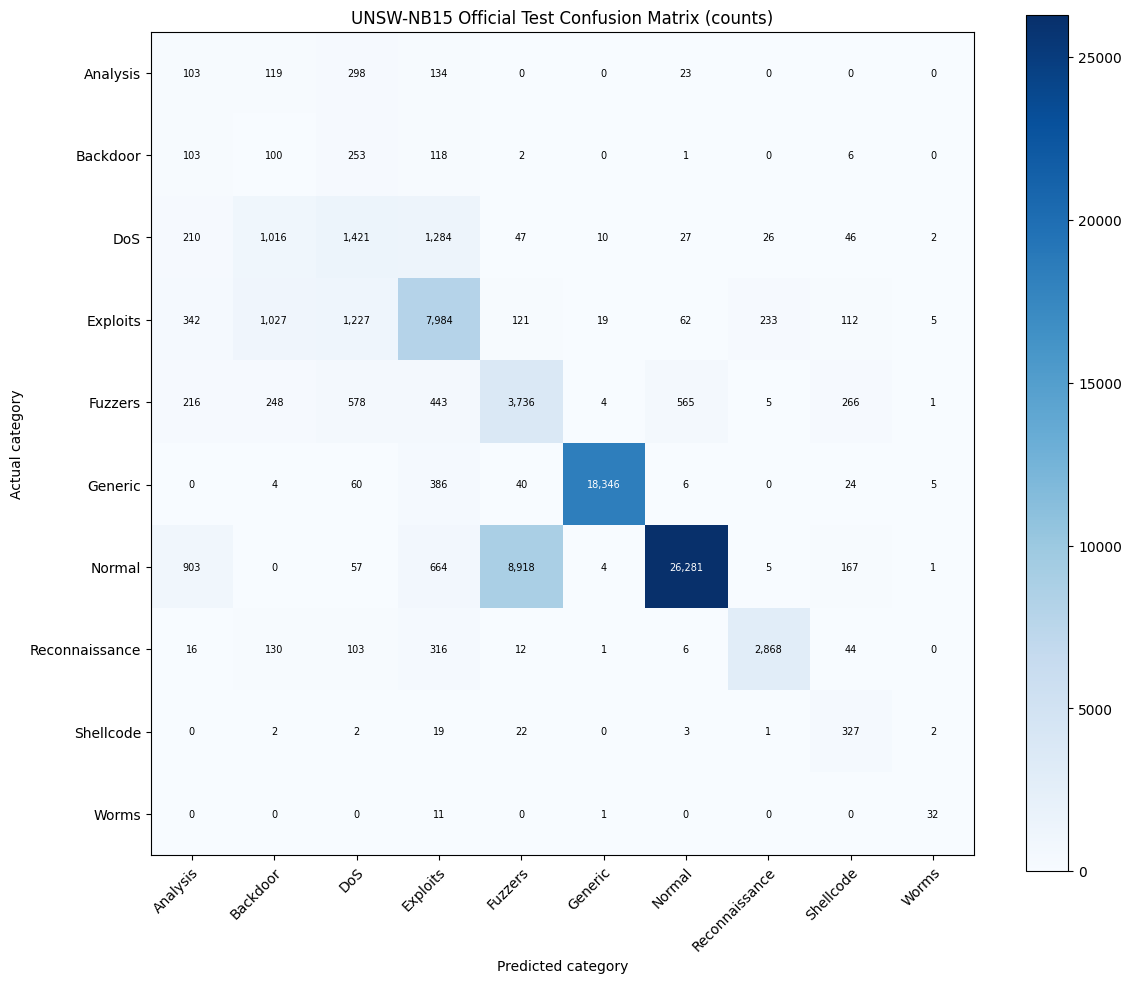

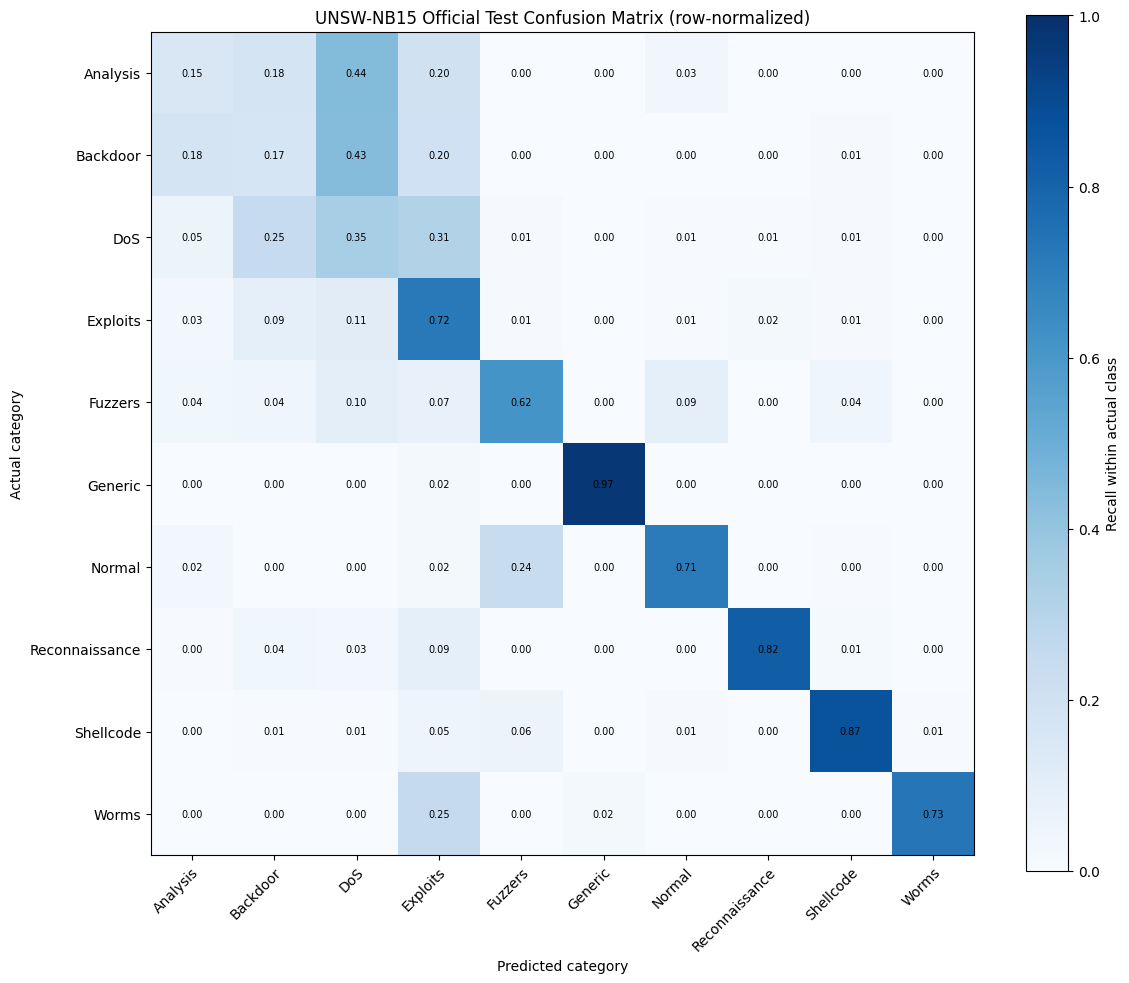

OFFICIAL TEST METRICS — FINAL EVALUATION
n_samples: 82332.000000
accuracy: 0.743308
balanced_accuracy: 0.609989
precision_macro: 0.532253
recall_macro: 0.609989
f1_macro: 0.544168
precision_weighted: 0.841978
recall_weighted: 0.743308
f1_weighted: 0.777808
fpr_macro_ovr: 0.028118
specificity_macro_ovr: 0.971882
normal_vs_attack_fpr: 0.289703
attack_detection_recall: 0.984713
matthews_corrcoef: 0.676133
log_loss: 0.601265
brier_score_multiclass: 0.326287
roc_auc_macro_ovr: 0.961737
average_precision_macro_ovr: 0.574662
top2_accuracy: 0.916606
training_seconds: 195.154920
test_prediction_seconds: 82.358897
inference_ms_per_record: 1.000327
test_records: 82332.000000
official_test_used_for_selection: 0.000000
official_test_evaluated_after_model_lock: 1.000000


,class,precision,recall,f1_score,specificity,false_positive_rate_ovr,support
0,Analysis,0.054411,0.152142,0.080156,0.978079,0.021921,677
1,Backdoor,0.037793,0.171527,0.061939,0.968856,0.031144,583
2,DoS,0.355339,0.347518,0.351385,0.967051,0.032949,4089
3,Exploits,0.702879,0.717212,0.709973,0.952598,0.047402,11132
4,Fuzzers,0.289657,0.616298,0.394093,0.879874,0.120126,6062
5,Generic,0.997879,0.972180,0.984861,0.999385,0.000615,18871
6,Normal,0.974309,0.710297,0.821615,0.984713,0.015287,37000
7,Reconnaissance,0.913958,0.820366,0.864637,0.996575,0.003425,3496
8,Shellcode,0.329637,0.865079,0.477372,0.991886,0.008114,378
9,Worms,0.666667,0.727273,0.695652,0.999806,0.000194,44


In [10]:
# This is the single official test evaluation after the model and preprocessing are locked.
y_test = normalize_target_values(test_df[TARGET], "official testing")
unknown_test_labels = sorted(set(y_test.unique()) - set(classes))
if unknown_test_labels:
    raise ValueError(f"Official testing set contains classes absent from training: {unknown_test_labels}")

prediction_start = time.perf_counter()
test_predictions = final_model.predict(X_test)
test_probabilities_aligned = align_model_probabilities(final_model, X_test, classes)
test_prediction_seconds = time.perf_counter() - prediction_start
inference_ms_per_record = 1000.0 * test_prediction_seconds / max(len(X_test), 1)

test_metrics, per_class_metrics, test_cm = calculate_metrics(
    y_test.to_numpy(), test_predictions, classes, test_probabilities_aligned
)
test_metrics.update({
    "training_seconds": float(final_training_seconds),
    "test_prediction_seconds": float(test_prediction_seconds),
    "inference_ms_per_record": float(inference_ms_per_record),
    "test_records": int(len(X_test)),
    "official_test_used_for_selection": False,
    "official_test_evaluated_after_model_lock": True
})
(METRICS_DIR / "official_test_metrics.json").write_text(json.dumps(test_metrics, indent=2))
per_class_metrics.to_csv(METRICS_DIR / "official_test_per_class_metrics.csv", index=False)

cm_df = pd.DataFrame(test_cm, index=classes, columns=classes)
cm_df.to_csv(METRICS_DIR / "official_test_confusion_matrix.csv", index_label="Actual / Predicted")
row_totals = test_cm.sum(axis=1, keepdims=True)
normalized_cm = np.divide(test_cm, row_totals, out=np.zeros_like(test_cm, dtype=float), where=row_totals > 0)
normalized_cm_df = pd.DataFrame(normalized_cm, index=classes, columns=classes)
normalized_cm_df.to_csv(METRICS_DIR / "official_test_confusion_matrix_normalized.csv", index_label="Actual / Predicted")

fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(test_cm, interpolation="nearest", cmap="Blues")
fig.colorbar(image, ax=ax)
ax.set(xticks=np.arange(len(classes)), yticks=np.arange(len(classes)),
       xticklabels=classes, yticklabels=classes,
       ylabel="Actual category", xlabel="Predicted category",
       title="UNSW-NB15 Official Test Confusion Matrix (counts)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
threshold = test_cm.max() / 2 if test_cm.size else 0
for i in range(test_cm.shape[0]):
    for j in range(test_cm.shape[1]):
        ax.text(j, i, f"{test_cm[i, j]:,}", ha="center", va="center",
                color="white" if test_cm[i, j] > threshold else "black", fontsize=7)
fig.tight_layout()
CONFUSION_FIG = FIGURES_DIR / "official_test_confusion_matrix.png"
fig.savefig(CONFUSION_FIG, dpi=250, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(normalized_cm, interpolation="nearest", cmap="Blues", vmin=0, vmax=1)
fig.colorbar(image, ax=ax, label="Recall within actual class")
ax.set(xticks=np.arange(len(classes)), yticks=np.arange(len(classes)),
       xticklabels=classes, yticklabels=classes,
       ylabel="Actual category", xlabel="Predicted category",
       title="UNSW-NB15 Official Test Confusion Matrix (row-normalized)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for i in range(normalized_cm.shape[0]):
    for j in range(normalized_cm.shape[1]):
        ax.text(j, i, f"{normalized_cm[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.tight_layout()
NORMALIZED_CONFUSION_FIG = FIGURES_DIR / "official_test_confusion_matrix_normalized.png"
fig.savefig(NORMALIZED_CONFUSION_FIG, dpi=250, bbox_inches="tight")
plt.show()

print("OFFICIAL TEST METRICS — FINAL EVALUATION")
for metric, value in test_metrics.items():
    if isinstance(value, (float, int)):
        print(f"{metric}: {value:.6f}")
    else:
        print(f"{metric}: {value}")
display(per_class_metrics)

## 10. Normal-versus-Attack risk summary and predictions

In [11]:
# Save one prediction per official test row and a compact Normal/Attack summary.
risk_labels = np.array([risk_level(label) for label in test_predictions])
confidence = test_probabilities_aligned.max(axis=1)
official_predictions = pd.DataFrame({
    "actual_attack_cat": y_test.to_numpy(),
    "predicted_attack_cat": test_predictions,
    "risk_level": risk_labels,
    "prediction_confidence": confidence
})
official_predictions.to_csv(RESULTS_DIR / "official_test_predictions.csv", index=False)

risk_distribution = official_predictions["risk_level"].value_counts().rename_axis("risk_level").reset_index(name="count")
risk_distribution.to_csv(METRICS_DIR / "normal_attack_summary.csv", index=False)
attack_distribution = official_predictions["predicted_attack_cat"].value_counts().rename_axis("predicted_attack_cat").reset_index(name="count")
attack_distribution.to_csv(METRICS_DIR / "predicted_attack_distribution.csv", index=False)

# Post-hoc dataset shift diagnostics. These are descriptive after final evaluation and must not be used to retune the model.
TEST_INGESTION_CONVERSION_REPORT.to_csv(METRICS_DIR / "posthoc_test_numeric_conversion_quality.csv", index=False)
test_binary_label = pd.to_numeric(test_df["label"], errors="coerce")
expected_test_binary_label = (y_test != "Normal").astype(int)
test_label_mismatch_count = int((test_binary_label.fillna(-999).to_numpy() != expected_test_binary_label.to_numpy()).sum())
test_id_values = pd.to_numeric(test_df["id"], errors="coerce")
test_id_audit = {
    "test_id_unique": bool(test_df["id"].is_unique),
    "test_id_monotonic_increasing": bool(test_id_values.is_monotonic_increasing),
    "test_id_min": float(test_id_values.min()),
    "test_id_max": float(test_id_values.max()),
    "test_binary_label_target_mismatches": test_label_mismatch_count,
    "id_used_as_predictor": False
}
(METRICS_DIR / "posthoc_test_id_and_label_audit.json").write_text(json.dumps(test_id_audit, indent=2))
train_class_pct = y_train_full.value_counts(normalize=True).rename("train_fraction")
test_class_pct = y_test.value_counts(normalize=True).rename("test_fraction")
class_shift = pd.concat([train_class_pct, test_class_pct], axis=1).fillna(0).reindex(classes).fillna(0)
class_shift["absolute_fraction_change"] = (class_shift["test_fraction"] - class_shift["train_fraction"]).abs()
class_shift.to_csv(METRICS_DIR / "posthoc_train_test_class_mix.csv")

def calculate_psi(train_values, test_values, bins=10):
    train_values = pd.Series(train_values).replace([np.inf, -np.inf], np.nan).dropna().to_numpy()
    test_values = pd.Series(test_values).replace([np.inf, -np.inf], np.nan).dropna().to_numpy()
    if len(train_values) == 0 or len(test_values) == 0:
        return np.nan
    quantiles = np.unique(np.quantile(train_values, np.linspace(0, 1, bins + 1)))
    if len(quantiles) < 3:
        return 0.0
    edges = quantiles.copy(); edges[0] = -np.inf; edges[-1] = np.inf
    train_hist, _ = np.histogram(train_values, bins=edges)
    test_hist, _ = np.histogram(test_values, bins=edges)
    train_pct = np.clip(train_hist / max(train_hist.sum(), 1), 1e-6, None)
    test_pct = np.clip(test_hist / max(test_hist.sum(), 1), 1e-6, None)
    return float(np.sum((test_pct - train_pct) * np.log(test_pct / train_pct)))

shift_rows = []
for col in raw_numeric_columns:
    train_values = X_train_raw[col].dropna()
    test_values = X_test_raw[col].dropna()
    if len(train_values) and len(test_values):
        ks_stat, ks_p = ks_2samp(train_values, test_values)
        psi_value = calculate_psi(train_values, test_values)
    else:
        ks_stat, ks_p, psi_value = np.nan, np.nan, np.nan
    shift_rows.append({"feature": col, "ks_statistic": float(ks_stat), "ks_p_value": float(ks_p), "psi": psi_value})
shift_df = pd.DataFrame(shift_rows).sort_values("psi", ascending=False, na_position="last")
shift_df.to_csv(METRICS_DIR / "posthoc_train_test_numeric_shift.csv", index=False)

unseen_category_rows = []
for col in categorical_columns:
    train_levels = set(X_train_raw[col].dropna().astype(str))
    test_levels = set(X_test_raw[col].dropna().astype(str))
    unseen = sorted(test_levels - train_levels)
    unseen_category_rows.append({
        "feature": col, "training_levels": len(train_levels),
        "testing_levels": len(test_levels), "unseen_testing_levels": " | ".join(unseen),
        "unseen_level_count": len(unseen)
    })
unseen_categories_df = pd.DataFrame(unseen_category_rows)
unseen_categories_df.to_csv(METRICS_DIR / "posthoc_unseen_test_categories.csv", index=False)

train_hashes = pd.util.hash_pandas_object(X_train_raw, index=False, categorize=True).astype("uint64")
test_hashes = pd.util.hash_pandas_object(X_test_raw, index=False, categorize=True).astype("uint64")
train_hash_set = set(train_hashes.tolist())
test_overlap_mask = test_hashes.isin(train_hash_set).to_numpy()
overlap_count = int(test_overlap_mask.sum())

# Report exact train/test predictor overlap by actual class. This is a post-hoc
# description of the fixed official partition, not a model-selection signal.
overlap_class_frame = pd.DataFrame({
    "actual_attack_cat": y_test.to_numpy(),
    "exact_feature_match_in_training": test_overlap_mask
})
overlap_by_class = overlap_class_frame.groupby("actual_attack_cat").agg(
    test_rows=("exact_feature_match_in_training", "size"),
    exact_overlap_rows=("exact_feature_match_in_training", "sum")
).reindex(classes, fill_value=0).reset_index()
overlap_by_class["no_exact_overlap_rows"] = overlap_by_class["test_rows"] - overlap_by_class["exact_overlap_rows"]
overlap_by_class["exact_overlap_percent"] = np.where(
    overlap_by_class["test_rows"] > 0,
    100.0 * overlap_by_class["exact_overlap_rows"] / overlap_by_class["test_rows"], 0.0
)
overlap_by_class.to_csv(METRICS_DIR / "posthoc_test_feature_overlap_by_class.csv", index=False)

# Compare performance on records whose raw feature vector was / was not seen in
# training. Macro metrics are averaged over classes actually present in each
# subset; `classes_present` is saved so absent rare classes are not hidden.
overlap_subset_rows = []
overlap_per_class_rows = []
y_test_array = y_test.to_numpy().astype(str)
pred_test_array = np.asarray(test_predictions).astype(str)
for subset_name, subset_mask in [
    ("exact_feature_overlap", test_overlap_mask),
    ("no_exact_feature_overlap", ~test_overlap_mask)
]:
    if not np.any(subset_mask):
        continue
    subset_true = y_test_array[subset_mask]
    subset_pred = pred_test_array[subset_mask]
    present_classes = [label for label in classes if np.any(subset_true == label)]
    subset_metrics, subset_per_class, _ = calculate_metrics(
        subset_true, subset_pred, present_classes, y_proba=None
    )
    overlap_subset_rows.append({
        "test_subset": subset_name,
        "rows": int(subset_mask.sum()),
        "classes_present": len(present_classes),
        "class_names_present": " | ".join(present_classes),
        "accuracy": subset_metrics["accuracy"],
        "macro_precision_over_present_classes": subset_metrics["precision_macro"],
        "macro_recall_over_present_classes": subset_metrics["recall_macro"],
        "macro_f1_over_present_classes": subset_metrics["f1_macro"],
        "weighted_f1": subset_metrics["f1_weighted"],
        "matthews_corrcoef": subset_metrics["matthews_corrcoef"]
    })
    subset_per_class.insert(0, "test_subset", subset_name)
    overlap_per_class_rows.append(subset_per_class)

pd.DataFrame(overlap_subset_rows).to_csv(
    METRICS_DIR / "posthoc_test_metrics_by_feature_overlap.csv", index=False
)
if overlap_per_class_rows:
    pd.concat(overlap_per_class_rows, ignore_index=True).to_csv(
        METRICS_DIR / "posthoc_test_per_class_by_feature_overlap.csv", index=False
    )

# For overlapped test vectors, identify whether the same training feature group
# was assigned one label or conflicting labels. This exposes target ambiguity.
train_hash_label_frame = pd.DataFrame({
    "feature_hash": train_hashes.to_numpy(),
    "train_label": y_train_full.to_numpy().astype(str)
})
train_labels_by_hash = train_hash_label_frame.groupby("feature_hash")["train_label"].agg(
    lambda values: tuple(sorted(set(values)))
)
test_train_label_sets = test_hashes.map(train_labels_by_hash)
ambiguous_training_match = test_train_label_sets.map(
    lambda labels: isinstance(labels, tuple) and len(labels) > 1
).to_numpy()
actual_label_present_in_train_group = np.array([
    isinstance(labels, tuple) and str(actual) in labels
    for labels, actual in zip(test_train_label_sets.to_numpy(), y_test_array)
], dtype=bool)
matched_conflict_rows = test_overlap_mask & ambiguous_training_match
matched_label_disagreement_rows = test_overlap_mask & ~actual_label_present_in_train_group
ambiguity_report = {
    "exact_overlap_test_rows": overlap_count,
    "overlap_rows_matching_conflicting_training_label_groups": int(matched_conflict_rows.sum()),
    "overlap_rows_whose_actual_test_label_is_absent_from_matching_training_label_set": int(matched_label_disagreement_rows.sum()),
    "interpretation": "A feature vector can be associated with more than one training label. Such collisions expose dataset-level label ambiguity; they are not repaired by preprocessing."
}
(METRICS_DIR / "posthoc_test_overlap_label_ambiguity.json").write_text(
    json.dumps(ambiguity_report, indent=2)
)

# Audit repetition and conflicting labels inside the official test partition itself.
test_group_frame = pd.DataFrame({
    "feature_hash": test_hashes.to_numpy(),
    "target": y_test_array
})
test_group_stats = test_group_frame.groupby("feature_hash").agg(
    rows=("target", "size"), unique_labels=("target", "nunique"),
    labels=("target", lambda values: " | ".join(sorted(set(values))))
).reset_index()
test_conflicting_groups = test_group_stats[test_group_stats["unique_labels"] > 1]
test_duplicate_feature_rows_after_first = int(len(test_group_frame) - len(test_group_stats))
test_repeated_feature_groups = int((test_group_stats["rows"] > 1).sum())
test_conflicting_group_rows = int(test_conflicting_groups["rows"].sum())
test_group_stats.to_csv(METRICS_DIR / "posthoc_test_feature_group_summary.csv", index=False)
test_conflicting_groups.to_csv(METRICS_DIR / "posthoc_test_conflicting_feature_groups.csv", index=False)

# Post-hoc feature profile for the held-out partition, generated only after its
# one final evaluation. This complements the train/test KS and PSI table.
test_feature_profile_rows = []
for col in raw_numeric_columns:
    series = pd.to_numeric(X_test_raw[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
    values = series.dropna()
    if len(values):
        q01, q25, median, q75, q99 = values.quantile([0.01, 0.25, 0.50, 0.75, 0.99])
        iqr = float(q75 - q25)
        outlier_count = int(((values < q25 - 1.5 * iqr) | (values > q75 + 1.5 * iqr)).sum()) if iqr > 0 else 0
        test_feature_profile_rows.append({
            "feature": col, "missing_count": int(series.isna().sum()),
            "zero_count": int((values == 0).sum()),
            "zero_percent": float((values == 0).mean() * 100),
            "negative_count": int((values < 0).sum()),
            "minimum": float(values.min()), "q01": float(q01),
            "q25": float(q25), "median": float(median),
            "q75": float(q75), "q99": float(q99),
            "maximum": float(values.max()),
            "iqr_outlier_count": outlier_count,
            "iqr_outlier_percent": float(outlier_count / len(values) * 100),
            "skewness": float(values.skew()) if len(values) > 2 else np.nan
        })
    else:
        test_feature_profile_rows.append({"feature": col, "missing_count": int(series.isna().sum())})
pd.DataFrame(test_feature_profile_rows).to_csv(
    METRICS_DIR / "posthoc_test_numeric_feature_profile.csv", index=False
)

test_categorical_rows = []
for col in categorical_columns:
    counts = X_test_raw[col].value_counts(dropna=False)
    for value, count in counts.items():
        test_categorical_rows.append({
            "feature": col,
            "category": "__MISSING__" if pd.isna(value) else str(value),
            "count": int(count), "percentage": float(count / len(X_test_raw) * 100)
        })
pd.DataFrame(test_categorical_rows).to_csv(
    METRICS_DIR / "posthoc_test_categorical_level_frequencies.csv", index=False
)

posthoc_partition_audit = {
    "exact_test_feature_rows_also_present_in_training": overlap_count,
    "test_overlap_fraction": float(overlap_count / max(len(X_test_raw), 1)),
    "test_class_distribution_checked_after_final_evaluation": True,
    "test_feature_shift_checked_after_final_evaluation": True,
    "overlap_per_class_report_saved": True,
    "overlap_vs_novel_test_performance_saved": True,
    "overlap_training_label_ambiguity_report": ambiguity_report,
    "test_unique_feature_groups": int(len(test_group_stats)),
    "test_duplicate_feature_rows_after_first": test_duplicate_feature_rows_after_first,
    "test_repeated_feature_groups": test_repeated_feature_groups,
    "test_conflicting_duplicate_feature_groups": int(len(test_conflicting_groups)),
    "test_rows_in_conflicting_duplicate_groups": test_conflicting_group_rows,
    "posthoc_test_feature_profile_saved": True,
    "posthoc_test_categorical_frequencies_saved": True,
    "warning": "Descriptive test-set diagnostics only; do not use these results to change or reselect the reported model."
}
(METRICS_DIR / "posthoc_partition_audit.json").write_text(json.dumps(posthoc_partition_audit, indent=2))

print("Official test prediction distribution:")
display(risk_distribution)
display(attack_distribution)
print("Post-hoc train/test class mix (descriptive only; no model retuning):")
display(class_shift.sort_values("absolute_fraction_change", ascending=False))
print("Largest numeric distribution differences:")
display(shift_df.head(15))
print("Unseen test categorical levels:")
display(unseen_categories_df)
print("Exact test feature-vector overlap with training:", f"{overlap_count:,} ({100*overlap_count/max(len(X_test_raw),1):.2f}%)")
print("Overlap by actual class:")
display(overlap_by_class)
print("Post-hoc performance on overlapping vs non-overlapping test rows:")
display(pd.DataFrame(overlap_subset_rows))
print("Overlap rows affected by conflicting training labels:", ambiguity_report)
print("Post-hoc test partition repeated/conflicting feature groups:", {
    "unique_feature_groups": int(len(test_group_stats)),
    "duplicate_rows_after_first": test_duplicate_feature_rows_after_first,
    "repeated_groups": test_repeated_feature_groups,
    "conflicting_groups": int(len(test_conflicting_groups)),
    "rows_in_conflicting_groups": test_conflicting_group_rows
})
print("Post-hoc test ID/label consistency audit:", test_id_audit)

Official test prediction distribution:


,risk_level,count
0,Attack,55358
1,Normal,26974


,predicted_attack_cat,count
0,Normal,26974
1,Generic,18385
2,Fuzzers,12898
3,Exploits,11359
4,DoS,3999
5,Reconnaissance,3138
6,Backdoor,2646
7,Analysis,1893
8,Shellcode,992
9,Worms,48


Post-hoc train/test class mix (descriptive only; no model retuning):


,train_fraction,test_fraction,absolute_fraction_change
attack_cat,,,
Normal,0.319378,0.449400,0.130022
Exploits,0.190446,0.135209,0.055237
Fuzzers,0.103706,0.073629,0.030078
DoS,0.069944,0.049665,0.020279
Reconnaissance,0.059832,0.042462,0.017370
Analysis,0.011406,0.008223,0.003184
Backdoor,0.009958,0.007081,0.002877
Shellcode,0.006462,0.004591,0.001871
Generic,0.228127,0.229206,0.001079


Largest numeric distribution differences:


... (4 outputs left out)

,actual_attack_cat,test_rows,exact_overlap_rows,no_exact_overlap_rows,exact_overlap_percent
0,Analysis,677,125,552,18.463811
1,Backdoor,583,4,579,0.686106
2,DoS,4089,2004,2085,49.009538
3,Exploits,11132,1802,9330,16.187567
4,Fuzzers,6062,261,5801,4.305510
5,Generic,18871,1722,17149,9.125113
6,Normal,37000,1472,35528,3.978378
7,Reconnaissance,3496,1138,2358,32.551487
8,Shellcode,378,13,365,3.439153
9,Worms,44,0,44,0.000000


Post-hoc performance on overlapping vs non-overlapping test rows:


,test_subset,rows,classes_present,class_names_present,accuracy,macro_precision_over_present_classes,macro_recall_over_present_classes,macro_f1_over_present_classes,weighted_f1,matthews_corrcoef
0,exact_feature_overlap,8541,9,Analysis | Backdoor | DoS | Exploits | Fuzzers...,0.514694,0.504738,0.433412,0.452838,0.578276,0.465951
1,no_exact_feature_overlap,73791,10,Analysis | Backdoor | DoS | Exploits | Fuzzers...,0.769769,0.544422,0.633021,0.564328,0.797419,0.703447


Overlap rows affected by conflicting training labels: {'exact_overlap_test_rows': 8541, 'overlap_rows_matching_conflicting_training_label_groups': 2660, 'overlap_rows_whose_actual_test_label_is_absent_from_matching_training_label_set': 4294, 'interpretation': 'A feature vector can be associated with more than one training label. Such collisions expose dataset-level label ambiguity; they are not repaired by preprocessing.'}
Post-hoc test partition repeated/conflicting feature groups: {'unique_feature_groups': 53946, 'duplicate_rows_after_first': 28386, 'repeated_groups': 6318, 'conflicting_groups': 575, 'rows_in_conflicting_groups': 8809}
Post-hoc test ID/label consistency audit: {'test_id_unique': True, 'test_id_monotonic_increasing': True, 'test_id_min': 1.0, 'test_id_max': 82332.0, 'test_binary_label_target_mismatches': 0, 'id_used_as_predictor': False}


## 11. Grouped permutation feature importance (training-only validation)

Feature importance is estimated on a validation fold from the training partition, not on the official test set. Each raw feature is permuted and all derived traffic features are recalculated, so the engineered variables remain consistent with their source fields. Importance is model reliance, not causation.

Training-only diagnostic split: 88,082 fit rows; 87,259 validation rows.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

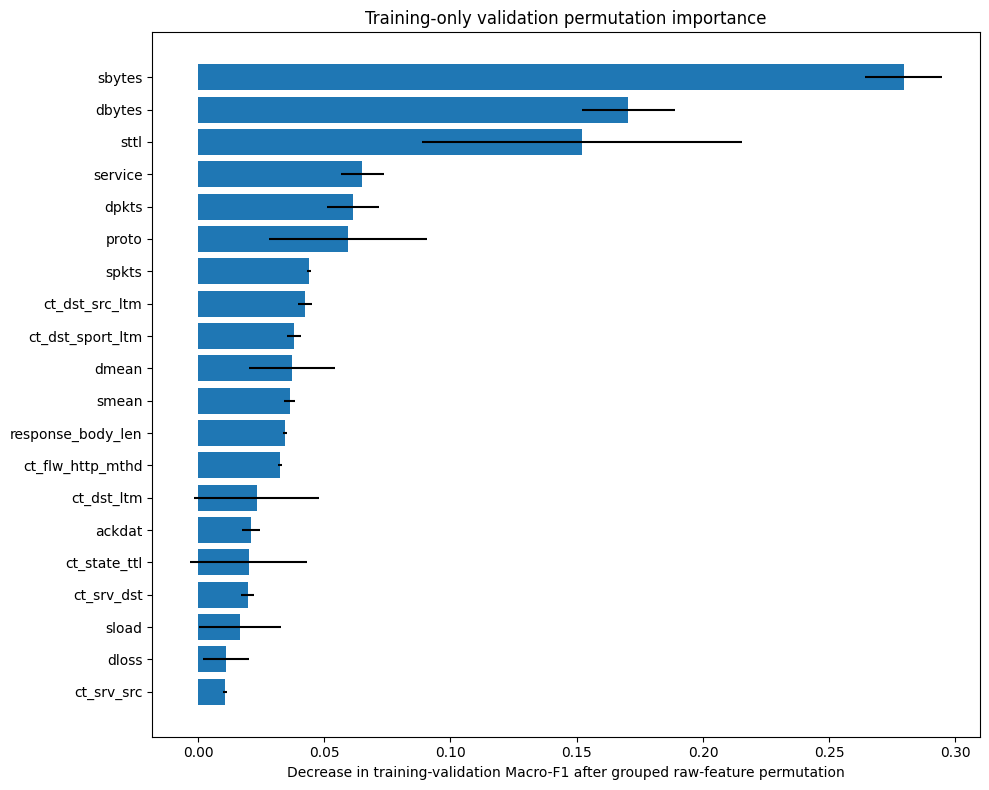

Diagnostic split Macro-F1: 0.6453


,feature,importance_mean,importance_std,validation_sample_size,repeats,derived_features_recomputed
6,sbytes,0.279532,0.015312,1000,2,True
7,dbytes,0.170508,0.018372,1000,2,True
9,sttl,0.152194,0.063473,1000,2,True
2,service,0.065127,0.008693,1000,2,True
5,dpkts,0.061358,0.010277,1000,2,True
1,proto,0.059372,0.031165,1000,2,True
4,spkts,0.043828,0.000789,1000,2,True
35,ct_dst_src_ltm,0.042321,0.002656,1000,2,True
34,ct_dst_sport_ltm,0.038036,0.002714,1000,2,True
27,dmean,0.037183,0.017197,1000,2,True


In [12]:
# Fit the selected configuration on fold-1 training rows and use fold-1 validation rows for diagnostics only.
diag_train_idx, diag_valid_idx = folds[DIAGNOSTIC_FOLD_INDEX]
X_diag_train = X_train.iloc[diag_train_idx].copy()
y_diag_train = y_train.iloc[diag_train_idx].copy()
X_diag_valid = X_train.iloc[diag_valid_idx].copy()
y_diag_valid = y_train.iloc[diag_valid_idx].copy()
X_diag_valid_raw = X_train_raw_current.iloc[diag_valid_idx].copy()

print(f"Training-only diagnostic split: {len(X_diag_train):,} fit rows; {len(X_diag_valid):,} validation rows.")
diagnostic_model = build_pipeline(SELECTED_MODEL, SELECTED_STRATEGY)
fit_candidate(diagnostic_model, SELECTED_MODEL, X_diag_train, y_diag_train)
diag_predictions = diagnostic_model.predict(X_diag_valid)
diag_probabilities = align_model_probabilities(diagnostic_model, X_diag_valid, classes)
diag_metrics, _, _ = calculate_metrics(y_diag_valid.to_numpy(), diag_predictions, classes, diag_probabilities)
(METRICS_DIR / "training_validation_diagnostic_metrics.json").write_text(json.dumps(diag_metrics, indent=2))

importance_n = min(IMPORTANCE_SAMPLE_SIZE, len(X_diag_valid_raw))
importance_rng = np.random.default_rng(RANDOM_STATE + 10)
importance_indices = importance_rng.choice(len(X_diag_valid_raw), size=importance_n, replace=False)
raw_importance_sample = X_diag_valid_raw.iloc[importance_indices].reset_index(drop=True)
y_importance = y_diag_valid.iloc[importance_indices].reset_index(drop=True)
base_importance_features = prepare_model_features(raw_importance_sample)
base_importance_predictions = diagnostic_model.predict(base_importance_features)
base_importance_score = f1_score(y_importance, base_importance_predictions, average="macro", zero_division=0)

importance_rows = []
for feature in RAW_FEATURE_COLUMNS:
    score_drops = []
    for repeat in range(IMPORTANCE_REPEATS):
        permuted_raw = raw_importance_sample.copy()
        permutation_rng = np.random.default_rng(RANDOM_STATE + 500 + repeat * 101 + RAW_FEATURE_COLUMNS.index(feature))
        permuted_raw[feature] = permutation_rng.permutation(permuted_raw[feature].to_numpy())
        permuted_features = prepare_model_features(permuted_raw)
        permuted_predictions = diagnostic_model.predict(permuted_features)
        permuted_score = f1_score(y_importance, permuted_predictions, average="macro", zero_division=0)
        score_drops.append(base_importance_score - permuted_score)
    importance_rows.append({
        "feature": feature,
        "importance_mean": float(np.mean(score_drops)),
        "importance_std": float(np.std(score_drops, ddof=1)) if len(score_drops) > 1 else 0.0,
        "validation_sample_size": int(importance_n),
        "repeats": int(IMPORTANCE_REPEATS),
        "derived_features_recomputed": True
    })
importance_df = pd.DataFrame(importance_rows).sort_values("importance_mean", ascending=False)
importance_df.to_csv(METRICS_DIR / "training_validation_permutation_importance.csv", index=False)

# Backward-compatible variable names for the Gradio dashboard and package exporter.
IMPORTANCE_FIG = FIGURES_DIR / "training_validation_permutation_importance.png"
top_importance = importance_df.head(20).sort_values("importance_mean")
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top_importance["feature"], top_importance["importance_mean"], xerr=top_importance["importance_std"])
ax.set_xlabel("Decrease in training-validation Macro-F1 after grouped raw-feature permutation")
ax.set_title("Training-only validation permutation importance")
fig.tight_layout()
fig.savefig(IMPORTANCE_FIG, dpi=250, bbox_inches="tight")
plt.show()
print("Diagnostic split Macro-F1:", round(diag_metrics["f1_macro"], 4))
display(importance_df.head(20))

## 12. TTL feature ablation (training-only validation)

The model is refitted without `sttl`, `dttl` and `ct_state_ttl` on the diagnostic training fold, then evaluated on that fold's held-out validation rows. This analysis does not inspect or tune against official test labels.

In [13]:
ttl_features = [c for c in feature_columns if c.lower() in {"sttl", "dttl", "ct_state_ttl"}]
full_diag_row = {"experiment": "Selected full-feature model", "removed_features": "", "number_removed": 0, **diag_metrics}
ablation_rows = [full_diag_row]
if ttl_features:
    retained_features = [c for c in feature_columns if c not in ttl_features]
    retained_numeric = [c for c in numeric_columns if c not in ttl_features]
    retained_categorical = [c for c in categorical_columns if c not in ttl_features]
    X_diag_train_reduced = X_diag_train[retained_features].copy()
    X_diag_valid_reduced = X_diag_valid[retained_features].copy()
    ablation_model = build_pipeline(
        SELECTED_MODEL, SELECTED_STRATEGY,
        numeric_cols=retained_numeric, categorical_cols=retained_categorical
    )
    fit_candidate(ablation_model, SELECTED_MODEL, X_diag_train_reduced, y_diag_train)
    ablation_predictions = ablation_model.predict(X_diag_valid_reduced)
    ablation_probabilities = align_model_probabilities(ablation_model, X_diag_valid_reduced, classes)
    ablation_metrics, _, _ = calculate_metrics(
        y_diag_valid.to_numpy(), ablation_predictions, classes, ablation_probabilities
    )
    ablation_rows.append({
        "experiment": "Without TTL-related features",
        "removed_features": ", ".join(ttl_features),
        "number_removed": len(ttl_features),
        **ablation_metrics
    })
    del ablation_model
    gc.collect()
else:
    print("No TTL-related features found; ablation could not be run.")
ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv(METRICS_DIR / "training_validation_ttl_ablation.csv", index=False)
print("TTL features removed:", ttl_features)
display(ablation_df)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


TTL features removed: ['sttl', 'dttl', 'ct_state_ttl']


,experiment,removed_features,number_removed,n_samples,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,...,fpr_macro_ovr,specificity_macro_ovr,normal_vs_attack_fpr,attack_detection_recall,matthews_corrcoef,log_loss,brier_score_multiclass,roc_auc_macro_ovr,average_precision_macro_ovr,top2_accuracy
0,Selected full-feature model,,0,87259,0.822586,0.637343,0.679082,0.637343,0.645319,0.839916,...,0.020490,0.979510,0.098858,0.979250,0.777767,0.430748,0.222469,0.969419,0.661353,0.949083
1,Without TTL-related features,"sttl, dttl, ct_state_ttl",3,87259,0.821382,0.621528,0.676375,0.621528,0.633023,0.838977,...,0.020641,0.979359,0.099608,0.979453,0.776221,0.435583,0.225034,0.968895,0.652367,0.949128


## 13. Controlled input-corruption robustness (training-only validation)

Noise, extreme-value and zero-replacement tests are applied to copies of the diagnostic validation fold from the training partition. Perturbation magnitudes are learned from the diagnostic training fold. These are synthetic input-quality tests, not real cyberattacks or adversarial-robustness certification.

In [14]:
def evaluate_robustness_condition(condition, raw_frame):
    prepared = prepare_model_features(raw_frame)
    predictions = diagnostic_model.predict(prepared)
    probabilities = align_model_probabilities(diagnostic_model, prepared, classes)
    metrics, _, _ = calculate_metrics(y_diag_valid.to_numpy(), predictions, classes, probabilities)
    return {"condition": condition, **metrics}

robustness_rows = [{"condition": "Clean training-validation fold", **diag_metrics}]

if raw_numeric_columns:
    gaussian_raw = X_diag_valid_raw.copy()
    noise_rng = np.random.default_rng(RANDOM_STATE + 101)
    for col in raw_numeric_columns:
        std = float(X_diag_train[col].std(skipna=True))
        if not np.isfinite(std):
            std = 0.0
        base = pd.to_numeric(gaussian_raw[col], errors="coerce")
        gaussian_raw[col] = base + noise_rng.normal(0.0, 0.01 * std, size=len(gaussian_raw))
    robustness_rows.append(evaluate_robustness_condition("Gaussian noise (1% of diagnostic-train SD)", gaussian_raw))

    extreme_raw = X_diag_valid_raw.copy()
    extreme_rng = np.random.default_rng(RANDOM_STATE + 102)
    for col in raw_numeric_columns:
        values = X_diag_train[col].dropna()
        if values.empty:
            continue
        q99 = float(values.quantile(0.99))
        iqr = float(values.quantile(0.75) - values.quantile(0.25))
        mask = extreme_rng.random(len(extreme_raw)) < 0.01
        extreme_raw.loc[mask, col] = q99 + 10.0 * max(iqr, 1.0)
    robustness_rows.append(evaluate_robustness_condition("Extreme values (1% of numeric cells)", extreme_raw))

    zero_raw = X_diag_valid_raw.copy()
    zero_rng = np.random.default_rng(RANDOM_STATE + 103)
    for col in raw_numeric_columns:
        mask = zero_rng.random(len(zero_raw)) < 0.05
        zero_raw.loc[mask, col] = 0.0
    robustness_rows.append(evaluate_robustness_condition("Zero replacement (5% of numeric cells)", zero_raw))

robustness_df = pd.DataFrame(robustness_rows)
robustness_df.to_csv(METRICS_DIR / "training_validation_robustness_results.csv", index=False)
display(robustness_df[["condition", "accuracy", "precision_macro", "recall_macro", "f1_macro", "fpr_macro_ovr", "normal_vs_attack_fpr"]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,condition,accuracy,precision_macro,recall_macro,f1_macro,fpr_macro_ovr,normal_vs_attack_fpr
0,Clean training-validation fold,0.822586,0.679082,0.637343,0.645319,0.020490,0.098858
1,Gaussian noise (1% of diagnostic-train SD),0.624669,0.520456,0.313653,0.314810,0.046425,0.122119
2,Extreme values (1% of numeric cells),0.816386,0.669767,0.625434,0.635600,0.021324,0.102711
3,Zero replacement (5% of numeric cells),0.793970,0.647538,0.570465,0.591142,0.024749,0.095398


## 14. Automated implementation tests

The tests cover leakage-column exclusion, matching train/test schemas, duplicate-group-safe screening, class coverage in both sampled folds, candidate inclusion, positive finite mild sample weights, prediction labels, metric ranges, confusion-matrix dimensions, model serialization, unseen categorical values and saved results. Fast mode checks two sampled grouped screening folds; full mode checks the five-fold confirmation result.

In [15]:
class NIDSPipelineTests(unittest.TestCase):
    def test_leakage_columns_excluded(self):
        self.assertFalse(set(EXCLUDED_PREDICTORS).intersection(X_train.columns))

    def test_schema_and_feature_preparation_match(self):
        self.assertEqual(list(X_train.columns), list(X_test.columns))
        rebuilt = prepare_model_features(X_train_raw_current.head(10))
        self.assertEqual(list(rebuilt.columns), list(X_train.columns))
        pd.testing.assert_frame_equal(rebuilt.reset_index(drop=True), X_train.head(10).reset_index(drop=True), check_dtype=False)

    def test_all_ten_classes_present(self):
        self.assertEqual(set(classes), set(EXPECTED_UNSW_CLASSES))

    def test_grouped_folds_cover_all_classes_and_no_duplicate_leakage(self):
        self.assertEqual(len(folds), N_SPLITS)
        self.assertEqual(len(screen_folds), SCREEN_SPLITS)
        if FAST_MODE:
            self.assertLess(len(screen_folds[0][0]), len(folds[0][0]) + len(folds[0][1]))
            self.assertEqual(len(TOP_MODELS), 2)
            self.assertEqual(len(cv_fold_results), (len(ACTIVE_CANDIDATE_MODELS) + 1) * SCREEN_SPLITS)
        for train_idx, valid_idx in folds:
            self.assertFalse(set(groups[train_idx]).intersection(set(groups[valid_idx])))
            self.assertEqual(set(y_train.iloc[train_idx]), set(classes))
            self.assertEqual(set(y_train.iloc[valid_idx]), set(classes))

    def test_screening_and_confirmation_counts(self):
        counts = cv_fold_results.groupby(["model", "preprocessing"]).size()
        self.assertTrue((counts == N_SPLITS).all())
        self.assertTrue((screen_results.groupby("model").size() == SCREEN_SPLITS).all())
        self.assertTrue(set(ACTIVE_CANDIDATE_MODELS).issubset(set(screen_results["model"])))

    def test_candidate_models_and_f1_selection(self):
        self.assertIn("XGBoost (Unweighted)", CANDIDATE_MODELS)
        self.assertIn("LightGBM (Regularized)", CANDIDATE_MODELS)
        self.assertIn("XGBoost (Regularized)", CANDIDATE_MODELS)
        self.assertIn("ExtraTrees (Unweighted)", CANDIDATE_MODELS)
        self.assertIn("Soft Voting (Unweighted)", CANDIDATE_MODELS)
        self.assertNotIn("CatBoost", " ".join(CANDIDATE_MODELS))
        self.assertIn("XGBoost (Mild Weights)", FAST_CANDIDATE_MODELS)
        self.assertIn("LightGBM (Mild Weights)", FAST_CANDIDATE_MODELS)
        self.assertEqual(SELECTION_METRIC, "macro_f1")
        self.assertAlmostEqual(ACCURACY_TOLERANCE, 0.015)

    def test_mild_sample_weights_are_finite_and_normalized(self):
        sample_y = np.array(["Normal"] * 90 + ["DoS"] * 9 + ["Worms"])
        weights = compute_mild_class_weights(sample_y)
        self.assertEqual(len(weights), len(sample_y))
        self.assertTrue(np.all(np.isfinite(weights)))
        self.assertTrue(np.all(weights > 0))
        self.assertAlmostEqual(float(weights.mean()), 1.0, places=6)
        self.assertGreater(weights[-1], weights[0])

    def test_engineered_features_exist_and_are_deterministic(self):
        self.assertTrue(len(DERIVED_FEATURE_COLUMNS) > 0)
        rebuilt = prepare_model_features(X_train_raw_current.head(10))
        self.assertTrue(set(DERIVED_FEATURE_COLUMNS).issubset(set(rebuilt.columns)))

    def test_comprehensive_dataset_audit_fields(self):
        self.assertEqual(audit["raw_predictor_count"], 42)
        self.assertEqual(audit["derived_predictor_count"], 7)
        self.assertEqual(audit["total_predictor_count"], 49)
        self.assertGreaterEqual(audit["high_correlation_pair_count_abs_spearman_ge_0_95"], audit["raw_numeric_high_correlation_pair_count_abs_spearman_ge_0_95"])
        self.assertGreater(audit["training_duplicate_feature_rows_after_first"], 0)
        self.assertGreater(audit["conflicting_duplicate_feature_groups"], 0)
        self.assertEqual(audit["official_test_labels_used_before_final_evaluation"], False)
        self.assertEqual(len(feature_quality_report), len(feature_columns))

    def test_record_id_and_binary_label_are_not_predictors(self):
        self.assertNotIn("id", X_train.columns)
        self.assertNotIn("label", X_train.columns)
        self.assertNotIn(TARGET, X_train.columns)
        self.assertFalse(audit["id_order_audit"]["id_used_as_predictor"])

    def test_probability_alignment(self):
        sample = X_test.head(20)
        probabilities = align_model_probabilities(final_model, sample, classes)
        self.assertEqual(probabilities.shape, (len(sample), len(classes)))
        self.assertTrue(np.all(np.isfinite(probabilities)))
        self.assertTrue(np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-5))

    def test_prediction_count_and_labels(self):
        self.assertEqual(len(test_predictions), len(y_test))
        self.assertTrue(set(test_predictions).issubset(set(classes)))

    def test_metric_ranges(self):
        for key in ["accuracy", "precision_macro", "recall_macro", "f1_macro", "fpr_macro_ovr", "normal_vs_attack_fpr"]:
            self.assertGreaterEqual(test_metrics[key], 0.0)
            self.assertLessEqual(test_metrics[key], 1.0)

    def test_confusion_matrix_dimensions(self):
        self.assertEqual(test_cm.shape, (len(classes), len(classes)))

    def test_official_test_not_used_for_diagnostics(self):
        self.assertTrue((METRICS_DIR / "training_validation_permutation_importance.csv").exists())
        self.assertTrue((METRICS_DIR / "training_validation_ttl_ablation.csv").exists())
        self.assertTrue((METRICS_DIR / "training_validation_robustness_results.csv").exists())

    def test_posthoc_test_overlap_diagnostics_exist(self):
        self.assertTrue((METRICS_DIR / "posthoc_test_feature_overlap_by_class.csv").exists())
        self.assertTrue((METRICS_DIR / "posthoc_test_metrics_by_feature_overlap.csv").exists())
        self.assertTrue((METRICS_DIR / "posthoc_test_per_class_by_feature_overlap.csv").exists())
        self.assertTrue((METRICS_DIR / "posthoc_test_overlap_label_ambiguity.json").exists())
        self.assertTrue((METRICS_DIR / "posthoc_test_feature_group_summary.csv").exists())
        self.assertTrue((METRICS_DIR / "posthoc_test_conflicting_feature_groups.csv").exists())
        self.assertTrue((METRICS_DIR / "posthoc_test_numeric_feature_profile.csv").exists())
        self.assertTrue((METRICS_DIR / "posthoc_test_categorical_level_frequencies.csv").exists())

    def test_model_serialization(self):
        bundle = joblib.load(MODEL_PATH)
        loaded = bundle["model"].predict(X_test.head(20))
        direct = final_model.predict(X_test.head(20))
        self.assertTrue(np.array_equal(loaded, direct))

    def test_unseen_categories(self):
        sample = X_test.head(10).copy()
        for col in categorical_columns:
            sample[col] = "__UNKNOWN_CATEGORY_TEST__"
        predictions = final_model.predict(sample)
        self.assertEqual(len(predictions), len(sample))

    def test_result_artifacts_exist(self):
        required = [
            MODEL_PATH,
            METRICS_DIR / "data_audit.json",
            METRICS_DIR / "feature_quality_profile.csv",
            METRICS_DIR / "high_correlation_pairs.csv",
            METRICS_DIR / "high_correlation_pairs_raw_numeric_only.csv",
            METRICS_DIR / "grouped_fold_coverage.csv",
            METRICS_DIR / "grouped_model_screening.csv",
            METRICS_DIR / "screening_performance_summary.csv",
            METRICS_DIR / VALIDATION_RESULTS_PATH.name,
            METRICS_DIR / "model_comparison_summary.csv",
            METRICS_DIR / "official_test_metrics.json",
            METRICS_DIR / "official_test_confusion_matrix.csv",
            METRICS_DIR / "posthoc_test_feature_overlap_by_class.csv",
            METRICS_DIR / "posthoc_test_metrics_by_feature_overlap.csv",
            METRICS_DIR / "posthoc_test_overlap_label_ambiguity.json",
            METRICS_DIR / "posthoc_test_feature_group_summary.csv",
            METRICS_DIR / "posthoc_test_numeric_feature_profile.csv",
            METRICS_DIR / "posthoc_test_categorical_level_frequencies.csv",
            METRICS_DIR / "training_validation_robustness_results.csv",
            IMPORTANCE_FIG, CONFUSION_FIG
        ]
        self.assertTrue(all(path.exists() for path in required))

suite = unittest.defaultTestLoader.loadTestsFromTestCase(NIDSPipelineTests)
test_stream = io.StringIO()
test_result = unittest.TextTestRunner(stream=test_stream, verbosity=2).run(suite)
test_log = test_stream.getvalue()
print(test_log)
(METRICS_DIR / "automated_tests.txt").write_text(test_log)
test_summary = {
    "tests_run": int(test_result.testsRun),
    "failures": len(test_result.failures),
    "errors": len(test_result.errors),
    "successful": bool(test_result.wasSuccessful())
}
(METRICS_DIR / "automated_test_summary.json").write_text(json.dumps(test_summary, indent=2))
if not test_result.wasSuccessful():
    raise RuntimeError("Automated tests failed; inspect automated_tests.txt.")
print("Automated tests passed.")

test_all_ten_classes_present (__main__.NIDSPipelineTests.test_all_ten_classes_present) ... ok
test_candidate_models_and_f1_selection (__main__.NIDSPipelineTests.test_candidate_models_and_f1_selection) ... ok
test_comprehensive_dataset_audit_fields (__main__.NIDSPipelineTests.test_comprehensive_dataset_audit_fields) ... ok
test_confusion_matrix_dimensions (__main__.NIDSPipelineTests.test_confusion_matrix_dimensions) ... ok
test_engineered_features_exist_and_are_deterministic (__main__.NIDSPipelineTests.test_engineered_features_exist_and_are_deterministic) ... ok
test_grouped_folds_cover_all_classes_and_no_duplicate_leakage (__main__.NIDSPipelineTests.test_grouped_folds_cover_all_classes_and_no_duplicate_leakage) ... ok
test_leakage_columns_excluded (__main__.NIDSPipelineTests.test_leakage_columns_excluded) ... ok
test_metric_ranges (__main__.NIDSPipelineTests.test_metric_ranges) ... ok
test_mild_sample_weights_are_finite_and_normalized (__main__.NIDSPipelineTests.test_mild_sample_weight

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## 15. Create the downloadable results package

This export includes the model, metrics, figures, predictions, and test log generated by your run. It does **not** create an academic report. Prepare the report only after reviewing these actual results.

In [16]:
experiment_summary = {
    "project": "Comprehensive Data-Audited Multiclass Network Intrusion Detection System",
    "dataset": "UNSW-NB15",
    "target": TARGET,
    "selected_model": SELECTED_MODEL,
    "selected_preprocessing": SELECTED_STRATEGY,
    "selection_metric": "macro_f1_with_accuracy_guardrail",
    "accuracy_tolerance_absolute": ACCURACY_TOLERANCE,
    "mild_class_weight_exponent": MILD_CLASS_WEIGHT_EXPONENT,
    "screening_folds": SCREEN_SPLITS,
    "selection_validation_folds": SCREEN_SPLITS if FAST_MODE else N_SPLITS,
    "final_confirmation_folds": 0 if FAST_MODE else N_SPLITS,
    "fast_mode": bool(FAST_MODE),
    "fast_screen_group_fraction": float(FAST_SCREEN_GROUP_FRACTION) if FAST_MODE else 1.0,
    "fast_screen_min_groups_per_class": int(FAST_SCREEN_MIN_GROUPS_PER_CLASS) if FAST_MODE else None,
    "reduced_estimators_during_model_selection": bool(FAST_MODE),
    "final_model_refit_uses_full_estimator_settings": True,
    "validation_protocol": "two sampled duplicate-grouped screening folds" if FAST_MODE else "three grouped screening folds + five grouped confirmation folds",
    "quick_run": bool(QUICK_RUN),
    "training_rows": int(len(X_train)),
    "official_testing_rows": int(len(X_test)),
    "raw_predictor_count": int(len(RAW_FEATURE_COLUMNS)),
    "engineered_predictor_count": int(len(DERIVED_FEATURE_COLUMNS)),
    "predictor_count": int(len(feature_columns)),
    "candidate_models": CANDIDATE_MODELS,
    "screening_finalists": TOP_MODELS,
    "preprocessing_finalists": PREPROCESSING_MODELS,
    "classes": classes,
    "official_test_metrics": test_metrics,
    "data_audit": audit,
    "diagnostic_metrics_training_validation": diag_metrics,
    "diagnostic_source": "training-only grouped validation fold",
    "posthoc_partition_audit": posthoc_partition_audit,
    "ttl_features_found": ttl_features,
    "automated_tests": test_summary,
    "academic_report_generated": False,
    "performance_note": "All performance values are reported as measured on the specified validation or official testing partition; no score is guaranteed."
}
(METRICS_DIR / "experiment_summary.json").write_text(
    json.dumps(experiment_summary, indent=2)
)

readme_text = f"""
# Comprehensive Data-Audited Multiclass NIDS — UNSW-NB15

Selected model: {SELECTED_MODEL}
Selected preprocessing: {SELECTED_STRATEGY}
Selection policy: Macro-F1 maximized among candidates within {100*ACCURACY_TOLERANCE:.1f} percentage points of the best mean validation accuracy
Validation protocol: {"2 sampled duplicate-grouped screening folds (reduced tree counts)" if FAST_MODE else "3 screening folds + 5 confirmation folds"}
Fast screen sampled-group fraction: {FAST_SCREEN_GROUP_FRACTION:.0%} (minimum {FAST_SCREEN_MIN_GROUPS_PER_CLASS} groups per class)

The project predicts all ten `attack_cat` classes. CatBoost is not included. Unweighted XGBoost remains a reference candidate; the comparison includes regularized and class-weighted XGBoost/LightGBM variants, tree ensembles and an XGBoost–LightGBM soft-voting ensemble.

The data audit checks schema and column integrity, canonical target labels, training-only binary-label consistency, numeric conversion failures, missing/infinite/negative values, zero inflation, ranges, percentiles, skew, IQR outliers, categorical cardinality, duplicate raw-feature groups, conflicting labels, class/group counts, highly correlated features, and grouped-fold class coverage. Features are reported, not automatically deleted based solely on outlier or correlation flags.

Model selection uses duplicate-grouped training-only validation. In FAST_MODE, nine candidates are tested on two sampled grouped folds with reduced estimator counts; this is a fast preliminary screen. The final model is refitted on the full training data using full estimator settings. Set FAST_MODE=False for the longer three-fold screening and five-fold confirmation protocol. Feature importance, TTL ablation and input-corruption robustness use a grouped validation fold from the training partition. The official testing labels are first used for the final evaluation after the model is locked. Post-hoc test-set class mix, numerical shift, unseen categories and train/test exact overlap are descriptive only and must not be used to retune or reselect this model.

The GUI uses the exact same `prepare_model_features()` function as the training pipeline; engineered features are recalculated from the uploaded raw fields. The model outputs ten-class predictions and class probabilities. The probability maximum is a model confidence estimate, not a guarantee of correctness.

This is an offline file-based prototype. It does not capture live packets, block connections or automatically respond to attacks. Report all scores as measured; no target accuracy is guaranteed.
"""


PACKAGE_ROOT = ROOT / "UNSW_NB15_F1_Optimized_Results"
if PACKAGE_ROOT.exists():
    shutil.rmtree(PACKAGE_ROOT)
for folder in ["metrics", "figures", "models", "predictions", "documentation"]:
    (PACKAGE_ROOT / folder).mkdir(parents=True, exist_ok=True)
shutil.copytree(METRICS_DIR, PACKAGE_ROOT / "metrics", dirs_exist_ok=True)
shutil.copytree(FIGURES_DIR, PACKAGE_ROOT / "figures", dirs_exist_ok=True)
shutil.copy2(MODEL_PATH, PACKAGE_ROOT / "models" / MODEL_PATH.name)
shutil.copy2(
    RESULTS_DIR / "official_test_predictions.csv",
    PACKAGE_ROOT / "predictions" / "official_test_predictions.csv"
)
(PACKAGE_ROOT / "documentation" / "README.md").write_text(
    readme_text.strip() + "\n"
)

requirements_text = """numpy>=1.26
pandas>=2.1
scikit-learn>=1.4,<2
scipy>=1.11
matplotlib>=3.8
joblib>=1.3
lightgbm>=4,<5
xgboost>=2,<4
gradio>=4.44,<6
"""
(PACKAGE_ROOT / "requirements.txt").write_text(requirements_text)
manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "selected_model": SELECTED_MODEL,
    "selected_preprocessing": SELECTED_STRATEGY,
    "selection_metric": "macro_f1_with_accuracy_guardrail",
    "accuracy_tolerance_absolute": ACCURACY_TOLERANCE,
    "validation_protocol": "two sampled duplicate-grouped screening folds" if FAST_MODE else "3 grouped screen folds plus 5 grouped confirmation folds",
    "fast_mode": bool(FAST_MODE),
    "mild_class_weight_exponent": MILD_CLASS_WEIGHT_EXPONENT,
    "quick_run": bool(QUICK_RUN),
    "academic_report_included": False,
    "comprehensive_data_audit": True,
    "test_used_for_model_selection": False,
    "diagnostics_source": "training-only grouped validation fold"
}
(PACKAGE_ROOT / "manifest.json").write_text(json.dumps(manifest, indent=2))

RESULTS_ZIP = ROOT / "UNSW_NB15_F1_Optimized_Results.zip"
with zipfile.ZipFile(RESULTS_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in PACKAGE_ROOT.rglob("*"):
        if path.is_file():
            archive.write(path, path.relative_to(PACKAGE_ROOT))
print("Results archive:", RESULTS_ZIP)
print("Archive size (MB):", round(RESULTS_ZIP.stat().st_size / 1e6, 2))
files.download(str(RESULTS_ZIP))


Results archive: /content/Robust_NIDS_UNSW_NB15_F1_Analysis/UNSW_NB15_F1_Optimized_Results.zip
Archive size (MB): 14.5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Interactive Gradio NIDS interface

The interface uses the selected trained pipeline and the same canonical `prepare_model_features()` function used during training. It supports single-record JSON analysis and batch CSV classification. Uploaded files must contain the original predictor fields; `id`, `label`, target fields and unrelated extra columns are never used as predictors. This remains offline file analysis, not live packet capture.


In [17]:
import gradio as gr

def prepare_prediction_frame(frame):
    # Reuse exactly the same feature-conversion and feature-engineering function as training.
    return prepare_model_features(frame)


def classify_single_record(json_text):
    try:
        record = json.loads(json_text)
        if not isinstance(record, dict):
            raise ValueError("Provide a single JSON object.")
        frame = prepare_prediction_frame(pd.DataFrame([record]))
        prediction = final_model.predict(frame)[0]
        probabilities = align_model_probabilities(final_model, frame, classes)[0]
        result = {
            "predicted_attack_category": str(prediction),
            "risk_level": risk_level(prediction),
            "confidence": float(np.max(probabilities)),
            "class_probabilities": {
                str(classes[i]): float(probabilities[i])
                for i in range(len(classes))
            },
            "input_rows_analyzed": 1,
            "note": "Prediction is based on the trained UNSW-NB15 model; confidence is a model probability, not a guarantee."
        }
        return json.dumps(result, indent=2)
    except Exception as exc:
        return json.dumps({"error": str(exc)}, indent=2)


def classify_batch_csv(file_path):
    try:
        if file_path is None:
            raise ValueError("Upload a CSV first.")
        if isinstance(file_path, dict):
            file_path = file_path.get("name")
        original = pd.read_csv(file_path, low_memory=False)
        model_input = prepare_prediction_frame(original)
        predictions = final_model.predict(model_input)
        probabilities = align_model_probabilities(final_model, model_input, classes)

        output = original.copy()
        output["predicted_attack_cat"] = predictions
        output["risk_level"] = [risk_level(p) for p in predictions]
        output["prediction_confidence"] = probabilities.max(axis=1)

        export_path = RESULTS_DIR / "gui_batch_predictions.csv"
        output.to_csv(export_path, index=False)
        distribution = (
            output["predicted_attack_cat"]
            .value_counts()
            .rename_axis("predicted_attack_cat")
            .reset_index(name="count")
        )
        return (
            output.head(100), distribution, str(export_path),
            f"Successfully classified {len(output):,} records."
        )
    except Exception as exc:
        return pd.DataFrame(), pd.DataFrame(), None, f"Error: {exc}"


overview = f"""
# UNSW-NB15 Network Intrusion Detection System

**Selected model:** {SELECTED_MODEL}

**Validation selection:** Macro-F1 maximized within {ACCURACY_TOLERANCE:.1%} of the best CV accuracy

**Preprocessing:** {SELECTED_STRATEGY}

**Official test accuracy:** {test_metrics['accuracy']:.4f}

**Official test balanced accuracy:** {test_metrics['balanced_accuracy']:.4f}

**Official test Macro-F1:** {test_metrics['f1_macro']:.4f}

**Official test weighted-F1:** {test_metrics['f1_weighted']:.4f}

**Normal-vs-Attack FPR:** {test_metrics['normal_vs_attack_fpr']:.4f}

**Inference latency:** {inference_ms_per_record:.5f} ms per record

**Predictors:** {len(feature_columns)} | **Classes:** {len(classes)}

**Training-only diagnostic Macro-F1:** {diag_metrics['f1_macro']:.4f}

**Dataset duplicate feature groups with conflicting labels:** {conflicting_duplicate_groups:,}
"""

with gr.Blocks(title="UNSW-NB15 Multiclass NIDS") as demo:
    gr.Markdown(overview)

    with gr.Tab("Single traffic record"):
        gr.Markdown("Paste one JSON record containing all required predictor fields.")
        single_input = gr.Code(label="Traffic record JSON", language="json", lines=12)
        single_button = gr.Button("Analyze traffic")
        single_output = gr.Code(label="Detection result", language="json")
        single_button.click(
            classify_single_record,
            inputs=single_input,
            outputs=single_output
        )

    with gr.Tab("Batch CSV"):
        csv_input = gr.File(
            label="Upload a CSV with required features",
            file_types=[".csv"],
            type="filepath"
        )
        batch_button = gr.Button("Classify CSV")
        batch_status = gr.Textbox(label="Status")
        batch_preview = gr.Dataframe(label="Prediction preview (first 100 rows)")
        batch_counts = gr.Dataframe(label="Predicted attack distribution")
        batch_download = gr.File(label="Download classified CSV")
        batch_button.click(
            classify_batch_csv,
            inputs=csv_input,
            outputs=[batch_preview, batch_counts, batch_download, batch_status]
        )

    with gr.Tab("Evaluation dashboard"):
        gr.Dataframe(value=per_class_metrics, label="Per-class official test metrics")
        gr.Image(value=str(CONFUSION_FIG), label="Official test confusion matrix")
        gr.Image(value=str(IMPORTANCE_FIG), label="Training-only validation feature importance")
        gr.Dataframe(value=robustness_df, label="Training-only validation robustness results")
        gr.Dataframe(value=ablation_df, label="Training-only validation TTL feature ablation")

    with gr.Tab("Dataset and model overview"):
        gr.JSON(value=experiment_summary)
        gr.Dataframe(value=class_distribution, label="Training class distribution")
        gr.Dataframe(value=attack_distribution, label="Official test predicted class distribution")
        gr.Dataframe(value=feature_quality_report.head(30), label="Training feature-quality profile (first 30 rows)")

    gr.Markdown(
        "Offline academic prototype. This interface does not capture live packets, "
        "block connections, or automatically respond to attacks."
    )

print("Launching Gradio. Keep the Colab runtime active while using the share link.")
demo.launch(share=True, debug=False)


Launching Gradio. Keep the Colab runtime active while using the share link.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9b178ee53c90938747.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
